# Generative AI: Make something new — companion notebook

Guest lecture by Dr. Jesse Roberts. This notebook holds the code behind the numbers and pictures on the slides: the tour of generative systems (grammar, L-system, letter-pair counting, texture synthesis, a Hopfield network, diffusion frames) and the autoencoder → VAE sequence on scikit-learn's 8×8 handwritten digits.

**To run it** you need Python 3 with NumPy, SciPy, scikit-learn and matplotlib. The tour runs in seconds. The second half trains six small networks (about 15 s each), so a full run takes a few minutes; trained weights are cached in `genai_weights/`, so a rerun skips training. Set `QUICK = True` for a fast smoke test (far fewer epochs, so the numbers will not match the slides).

The networks are written in plain NumPy, with hand-written backprop and Adam, so that every number printed here matches the slides exactly. The same two networks can be opened in Torch Canvas, which writes the equivalent PyTorch: [autoencoder](https://jessetnroberts.github.io/torch-canvas/?open=autoencoder_digits) and [VAE](https://jessetnroberts.github.io/torch-canvas/?open=vae_digits).

Every number below is computed here from fixed seeds; the only exception is the LLM's next-word bars, which are illustrative.

Notation: p̂ is a predicted probability, ŷ a logit (`p_hat`, `y_hat` in code). For the VAE: z is the code, q̂(z | x) the encoder's distribution, with mean μ, log-variance log σ², spread σ, and noise ε.

In [1]:
import math
import random
import re
import time
from collections import Counter, defaultdict
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse
from scipy.stats import norm
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

QUICK = False   # True: train each network for a few epochs only (a smoke test; numbers will not match the slides)

# slide colours
BLUE = "#2557D6"
ORANGE = "#C2510F"
INK = "#16181D"
GREY = "#8E94A0"

WEIGHTS_DIR = Path("genai_weights")   # trained networks are cached here, so a rerun skips training
WEIGHTS_DIR.mkdir(exist_ok=True)


def show_image(ax, image, caption=None, vmin=0.0, vmax=1.0):
    """Draw one square greyscale image (ink dark) with an optional caption underneath."""
    side = int(round(np.sqrt(np.size(image))))
    ax.imshow(np.reshape(image, (side, side)), cmap="gray_r", vmin=vmin, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    if caption is not None:
        ax.set_xlabel(caption, fontsize=8)


def show_row(images, captions, title, row_label=None):
    """A row of small images, one caption each, under one title."""
    fig, axes = plt.subplots(1, len(images), figsize=(1.2 * len(images), 1.9))
    for ax, image, caption in zip(axes, images, captions):
        show_image(ax, image, caption)
    if row_label is not None:
        axes[0].set_ylabel(row_label)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Every stop samples from a joint distribution

Count which letter follows which in the 16 round 1 example words (with `^` for start and `$` for end). The counts are a joint p̂(previous, next); dividing by a row total gives a conditional. Notice that p̂(e | k) = p̂(k, e) / p̂(k) = 4/9, and that a whole word's probability is one conditional per letter, multiplied.

In [2]:
EXAMPLE_WORDS = ["kamino", "sutera", "tomeken", "risuka", "yonkira", "nabutan", "kesobi", "hiyome",
                 "maruten", "sakudo", "bontaku", "tezuran", "wakeri", "gomise", "punaro", "dokemu"]
START = "^"
END = "$"


def count_letter_pairs(words):
    """How often each letter follows each other letter, with start and end as extra letters."""
    counts = defaultdict(Counter)
    for word in words:
        marked = START + word + END
        for previous, following in zip(marked, marked[1:]):
            counts[previous][following] += 1
    return counts


def chain_factors(word, counts):
    """The conditionals p̂(next letter | previous letter) whose product is p̂(word)."""
    marked = START + word + END
    factors = []
    for previous, following in zip(marked, marked[1:]):
        row_total = sum(counts[previous].values())
        factors.append(Fraction(counts[previous][following], row_total))
    return factors


pair_counts = count_letter_pairs(EXAMPLE_WORDS)
n_pairs = sum(sum(row.values()) for row in pair_counts.values())
after_k = pair_counts["k"]
k_total = sum(after_k.values())

print("letters after k:", dict(after_k.most_common()), f"(of {k_total}; {n_pairs} pairs in all)")
print(f"p̂(k, e) = {after_k['e']}/{n_pairs}")
print(f"p̂(k)    = {k_total}/{n_pairs}")
print(f"p̂(e | k) = p̂(k, e) / p̂(k) = {Fraction(after_k['e'], k_total)}")

factors = chain_factors("makuton", pair_counts)
p_hat_makuton = math.prod(factors)
print()
print("p̂(makuton) =", " · ".join(str(f) for f in factors))
print(f"           = 1/{p_hat_makuton.denominator:,} ≈ {float(p_hat_makuton):.1e}")

letters after k: {'e': 4, 'a': 2, 'u': 2, 'i': 1} (of 9; 118 pairs in all)
p̂(k, e) = 4/118
p̂(k)    = 9/118
p̂(e | k) = p̂(k, e) / p̂(k) = 4/9

p̂(makuton) = 1/16 · 1/6 · 1/4 · 2/9 · 1/3 · 1/6 · 1/5 · 4/9
           = 1/349,920 ≈ 2.9e-06


## Stop 1: a grammar

Start at S and keep rewriting the leftmost symbol with one of its rules, chosen uniformly. Each choice multiplies the sentence's probability by 1/(number of rules for that symbol), so the run on the slide has p̂ = 1/3456.

In [3]:
GRAMMAR = {"S": [["NP", "VP"]],
           "NP": [["Det", "N"], ["Det", "Adj", "N"]],
           "VP": [["V", "NP"], ["V"]],
           "Det": [["the"], ["a"]],
           "Adj": [["green"], ["tiny"], ["sleepy"]],
           "N": [["cat"], ["robot"], ["student"]],
           "V": [["sees"], ["builds"], ["follows"], ["sleeps"]]}


def derive(rng):
    """Rewrite the leftmost non-word until only words remain; return every step and each choice's probability."""
    form = ["S"]
    steps = [form]
    factors = []
    while any(symbol in GRAMMAR for symbol in form):
        i = next(k for k, symbol in enumerate(form) if symbol in GRAMMAR)
        rules = GRAMMAR[form[i]]
        form = form[:i] + rng.choice(rules) + form[i + 1:]
        steps.append(form)
        factors.append(Fraction(1, len(rules)))   # every rule for this symbol is equally likely
    return steps, factors


rng = random.Random(5)
steps, factors = derive(rng)
print(" ".join(steps[0]))
running = Fraction(1)
for step, factor in zip(steps[1:], factors):
    running *= factor
    print(f"⇒ {' '.join(step):<30} ×{str(factor):<4}  running p̂ = {running}")
print("p̂(this run) =", math.prod(factors))

first_sentence = " ".join(steps[-1])
more_runs = []
while len(more_runs) < 4:          # four more sentences, all different
    sentence = " ".join(derive(rng)[0][-1])
    if sentence not in more_runs and sentence != first_sentence:
        more_runs.append(sentence)
print("\nMore runs:")
for sentence in more_runs:
    print(" ", sentence)

S
⇒ NP VP                          ×1     running p̂ = 1
⇒ Det Adj N VP                   ×1/2   running p̂ = 1/2
⇒ the Adj N VP                   ×1/2   running p̂ = 1/4
⇒ the tiny N VP                  ×1/3   running p̂ = 1/12
⇒ the tiny cat VP                ×1/3   running p̂ = 1/36
⇒ the tiny cat V NP              ×1/2   running p̂ = 1/72
⇒ the tiny cat builds NP         ×1/4   running p̂ = 1/288
⇒ the tiny cat builds Det N      ×1/2   running p̂ = 1/576
⇒ the tiny cat builds a N        ×1/2   running p̂ = 1/1152
⇒ the tiny cat builds a robot    ×1/3   running p̂ = 1/3456
p̂(this run) = 1/3456

More runs:
  the sleepy cat builds a green robot
  the student builds
  the cat builds a robot
  the student sleeps the tiny robot


## Stop 2: an L-system

One rewrite rule, F → FF−[−F+F+F]+[+F−F−F], applied to every F at once, four times. A turtle then reads the string: F draws a step, + and − turn 22.5°, [ and ] save and restore its position. Notice how fast the string grows: 1 → 20 → 172 → 1,388 → 11,116 symbols.

symbols after each rewrite: 1 → 20 → 172 → 1,388 → 11,116


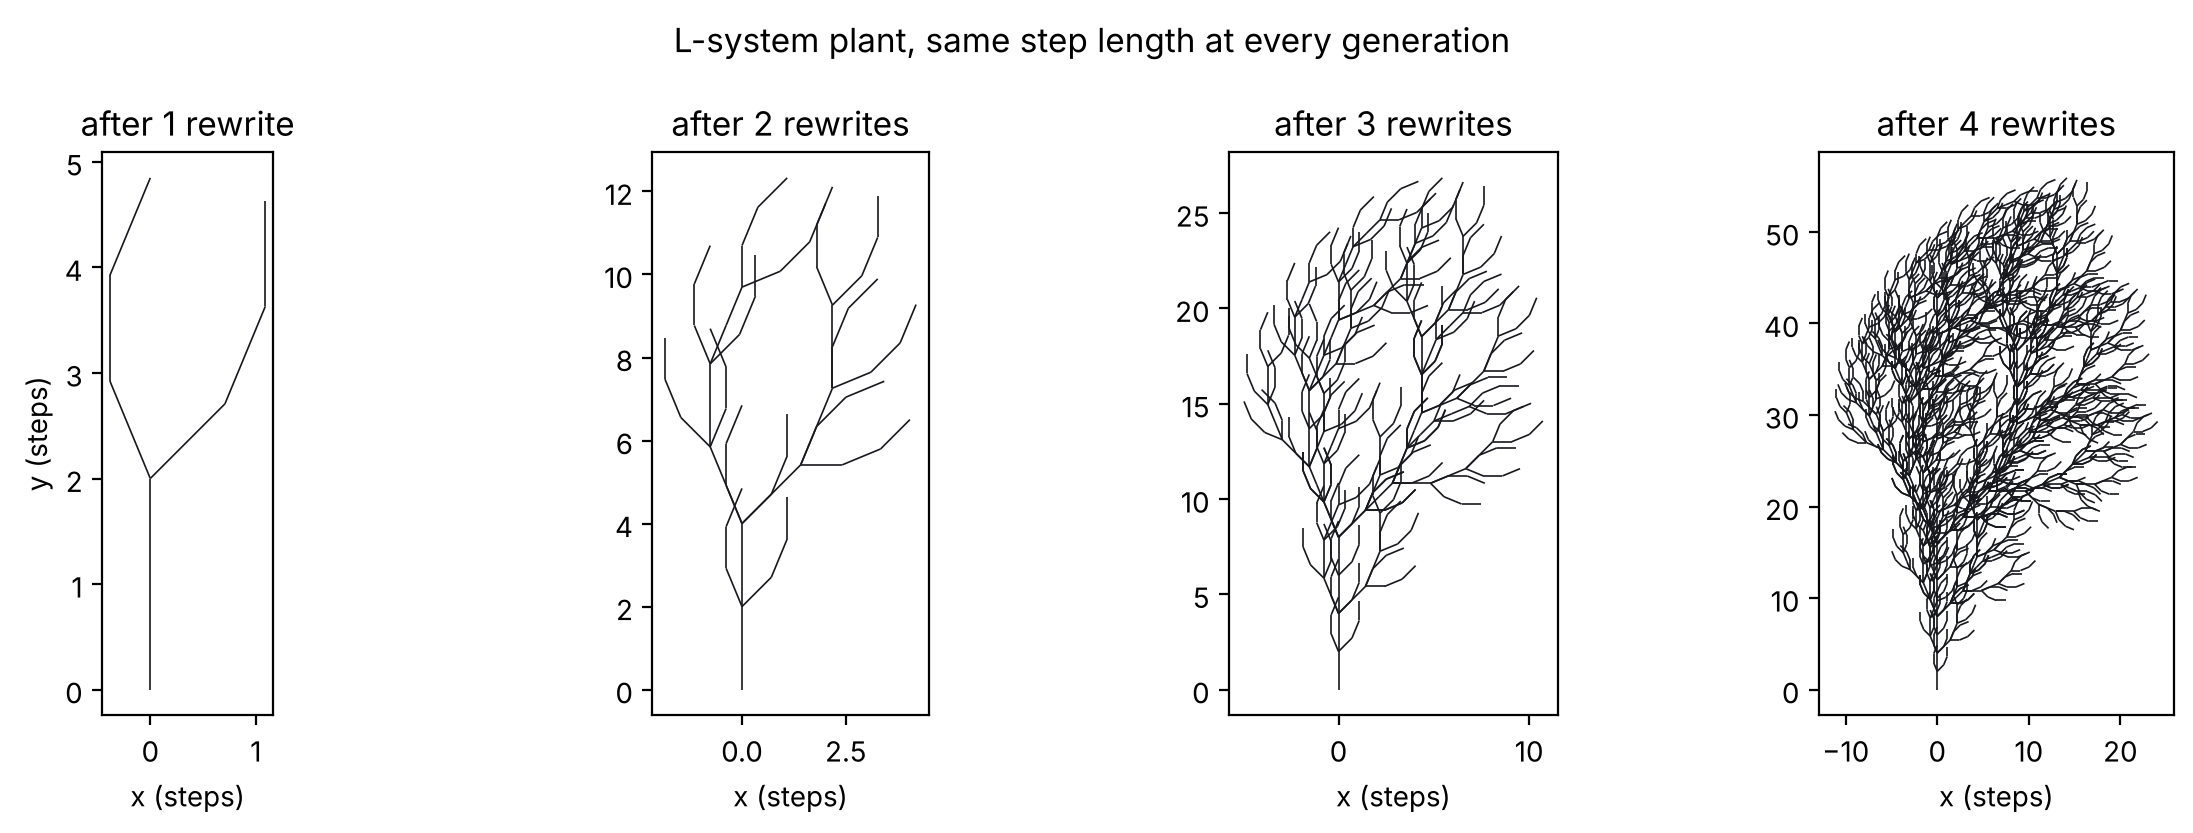

In [4]:
AXIOM = "F"
RULES = {"F": "FF-[-F+F+F]+[+F-F-F]"}
ANGLE = 22.5
N_REWRITES = 4


def rewrite(string):
    """Apply the rules to every symbol at once."""
    return "".join(RULES.get(symbol, symbol) for symbol in string)


def turtle_segments(string, angle):
    """Line segments drawn by a turtle reading the string, starting at (0, 0) facing up."""
    x, y, heading = 0.0, 0.0, 90.0
    stack = []
    segments = []
    for symbol in string:
        if symbol == "F":
            new_x = x + math.cos(math.radians(heading))
            new_y = y + math.sin(math.radians(heading))
            segments.append([(x, y), (new_x, new_y)])
            x, y = new_x, new_y
        elif symbol == "+":
            heading += angle
        elif symbol == "-":
            heading -= angle
        elif symbol == "[":
            stack.append((x, y, heading))
        elif symbol == "]":
            x, y, heading = stack.pop()
    return segments


strings = [AXIOM]
for _ in range(N_REWRITES):
    strings.append(rewrite(strings[-1]))
print("symbols after each rewrite:", " → ".join(f"{len(s):,}" for s in strings))

fig, axes = plt.subplots(1, N_REWRITES, figsize=(12, 4.2))
for generation, ax in zip(range(1, N_REWRITES + 1), axes):
    segments = np.array(turtle_segments(strings[generation], ANGLE))
    ax.add_collection(LineCollection(segments, colors=INK, linewidths=0.6))
    ax.autoscale()
    ax.set_aspect("equal")
    ax.set_title(f"after {generation} rewrite{'s' if generation > 1 else ''}")
    ax.set_xlabel("x (steps)")
axes[0].set_ylabel("y (steps)")
fig.suptitle("L-system plant, same step length at every generation")
fig.tight_layout()
plt.show()

## Stop 3: counting

Sample new words from the letter-pair counts: start at `^`, draw each next letter in proportion to its count after the previous one, stop at `$`. Each word is checked against round 1's rule. Notice the high valid rate over 2,000 samples, and how small even a valid word's chain probability is.

*Note:* the slide says none of the words are copies. That holds for the twelve words shown; among the 2,000 samples, 2 are copies of an example word (the valid rate, 94.7%, is unaffected at the slide's precision).

In [5]:
ROUND1_RULE = re.compile(r"^(?:[bcdfghjklmnpqrstvwxyz][aeiou]n?)+$")   # consonant, vowel, optional n; repeated
MAX_LENGTH = 24                                                        # stop runaway words


def sample_word(rng, counts):
    """Draw letters one at a time from p̂(next letter | previous letter) until the end mark."""
    word = ""
    previous = START
    while True:
        row = counts[previous]
        previous = rng.choices(list(row), weights=list(row.values()))[0]
        if previous == END or len(word) >= MAX_LENGTH:
            return word
        word += previous


rng = random.Random(4)
new_words = []
while len(new_words) < 12:            # twelve different, non-empty words
    word = sample_word(rng, pair_counts)
    if word and word not in new_words:
        new_words.append(word)
for word in new_words:
    mark = "✓" if ROUND1_RULE.match(word) else "✗"
    copied = "  (copied from the examples)" if word in EXAMPLE_WORDS else ""
    print(f"{word:<24} {mark}{copied}")

many_words = [sample_word(random.Random(1000 + i), pair_counts) for i in range(2000)]
n_valid = sum(bool(ROUND1_RULE.match(w)) for w in many_words)
n_copies = sum(w in EXAMPLE_WORDS for w in many_words)
print(f"\n2,000 samples: {n_valid / len(many_words):.1%} follow round 1's rule; {n_copies} are copies of an example word")

first_word = new_words[0]
p_hat_first = math.prod(chain_factors(first_word, pair_counts))
print(f"p̂({first_word}) = " + " · ".join(str(f) for f in chain_factors(first_word, pair_counts)))
print(f"      = {float(p_hat_first):.2e}")

sukamemakan              ✓
sutakura                 ✓
makuton                  ✓
so                       ✓
pudokezudomerakameken    ✓
domi                     ✓
te                       ✓
tokami                   ✓
hisudontaro              ✓
takemezuterakera         ✓
wa                       ✓
kukamisa                 ✓

2,000 samples: 94.7% follow round 1's rule; 2 are copies of an example word
p̂(sukamemakan) = 1/8 · 2/5 · 1/9 · 2/9 · 1/12 · 1/3 · 1/10 · 1/6 · 1/4 · 2/9 · 1/6 · 4/9
      = 2.35e-09


## Stop 4: texture synthesis

The sample is a 24×24 brick wall drawn in code. The output grows outward from a 3×3 seed: the next pixel is the empty one with the most filled neighbours, and it copies the centre of a random sample patch whose 9×9 surroundings match the filled part best (within 10% of the best match). Notice the output is bigger than the sample yet keeps its brick structure.

mortar share (pixels < 0.4): sample 0.24, grown 0.24


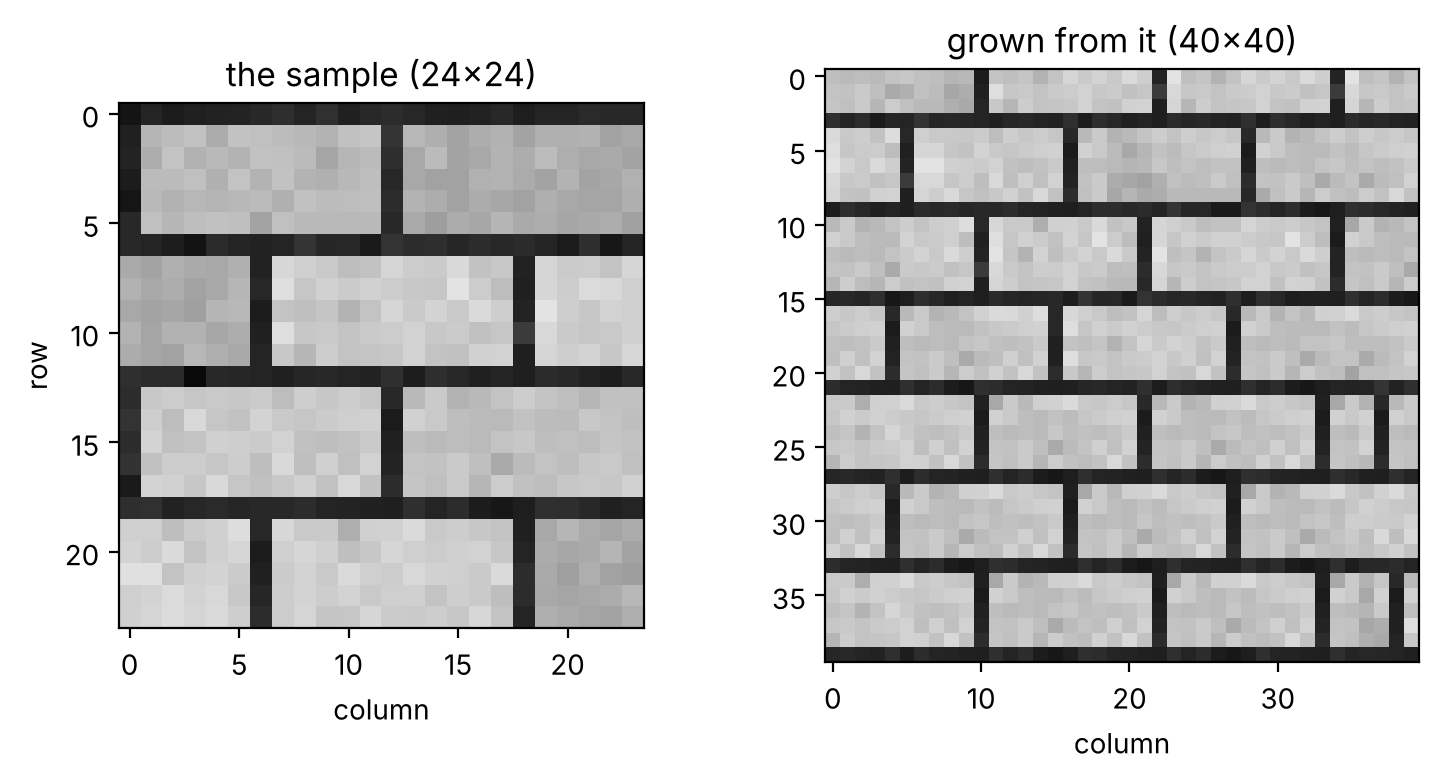

In [6]:
SAMPLE_SIZE = 24
WINDOW = 9
OUTPUT_SIZE = 40


def make_brick_sample(rng, size=SAMPLE_SIZE):
    """A brick wall: mortar 0.15, bricks about 0.75 with a small per-brick shade, plus pixel noise."""
    sample = np.full((size, size), 0.15)
    for top in range(0, size, 6):
        offset = 0 if (top // 6) % 2 == 0 else 6        # every other course is shifted half a brick
        for left in range(-12, size, 12):
            shade = rng.uniform(-0.08, 0.08)
            for r in range(top + 1, min(top + 6, size)):
                for c in range(left + offset + 1, left + offset + 12):
                    if 0 <= c < size:
                        sample[r, c] = 0.75 + shade
    noise = rng.normal(0, 0.03, sample.shape)
    return np.clip(sample + noise, 0, 1)


def grow_texture(sample, rng, window=WINDOW, out_size=OUTPUT_SIZE):
    """Efros & Leung: fill pixels one at a time by copying from the best-matching sample neighbourhoods."""
    half = window // 2
    size = len(sample)
    patches = []
    centres = []
    for i in range(half, size - half):
        for j in range(half, size - half):
            patches.append(sample[i - half:i + half + 1, j - half:j + half + 1])
            centres.append(sample[i, j])
    patches = np.array(patches)
    centres = np.array(centres)
    offsets = np.arange(window) - half
    gauss = np.exp(-(offsets[:, None] ** 2 + offsets[None, :] ** 2) / (2 * (window / 6.4) ** 2))  # near pixels count more

    out = np.zeros((out_size, out_size))
    known = np.zeros((out_size, out_size), bool)
    mid = out_size // 2
    out[mid - 1:mid + 2, mid - 1:mid + 2] = sample[10:13, 10:13]   # a 3x3 seed from the sample
    known[mid - 1:mid + 2, mid - 1:mid + 2] = True
    while not known.all():
        # the empty pixel with the most filled neighbours goes next
        padded_known = np.pad(known, 1)
        n_neighbours = np.zeros(padded_known.shape, int)
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                n_neighbours += np.roll(np.roll(padded_known, di, 0), dj, 1)
        n_neighbours = n_neighbours[1:-1, 1:-1]
        n_neighbours[known] = -1
        i, j = np.unravel_index(np.argmax(n_neighbours), n_neighbours.shape)
        # compare only the filled part of its window with every sample patch
        neighbourhood = np.pad(out, half)[i:i + window, j:j + window]
        weight = np.pad(known, half)[i:i + window, j:j + window] * gauss
        distance = ((patches - neighbourhood) ** 2 * weight).sum((1, 2)) / weight.sum()
        good = np.flatnonzero(distance <= distance.min() * 1.1 + 1e-9)
        out[i, j] = centres[rng.choice(good)]
        known[i, j] = True
    return out


rng = np.random.default_rng(0)
brick_sample = make_brick_sample(rng)
grown = grow_texture(brick_sample, rng)
print(f"mortar share (pixels < 0.4): sample {(brick_sample < 0.4).mean():.2f}, grown {(grown < 0.4).mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4), gridspec_kw={"width_ratios": [SAMPLE_SIZE, OUTPUT_SIZE]})
for ax, image, title in zip(axes, [brick_sample, grown], ["the sample (24×24)", "grown from it (40×40)"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("column")
axes[0].set_ylabel("row")
fig.tight_layout()
plt.show()

## Stop 5: an energy landscape

A Hopfield network stores three 10×10 patterns (+, =, ring) in its weights with the Hebbian rule. Start from a + with 30 pixels flipped and update units one at a time, each taking the sign of its weighted input. Notice the energy only goes down, and after 30 flips the + is back.

start energy -7.3; 30 flips; end energy -55.7
energy after each flip: [-7.8, -9.0, -10.1, -10.7, -12.0, -12.7, -13.6, -14.9, -16.3, -17.9, -19.4, -21.0, -22.7, -24.5, -25.4, -27.4, -29.4, -31.6, -33.9, -36.3, -38.4, -39.6, -42.2, -45.0, -45.8, -48.6, -49.4, -52.3, -53.3, -55.7]
back to the stored +: True


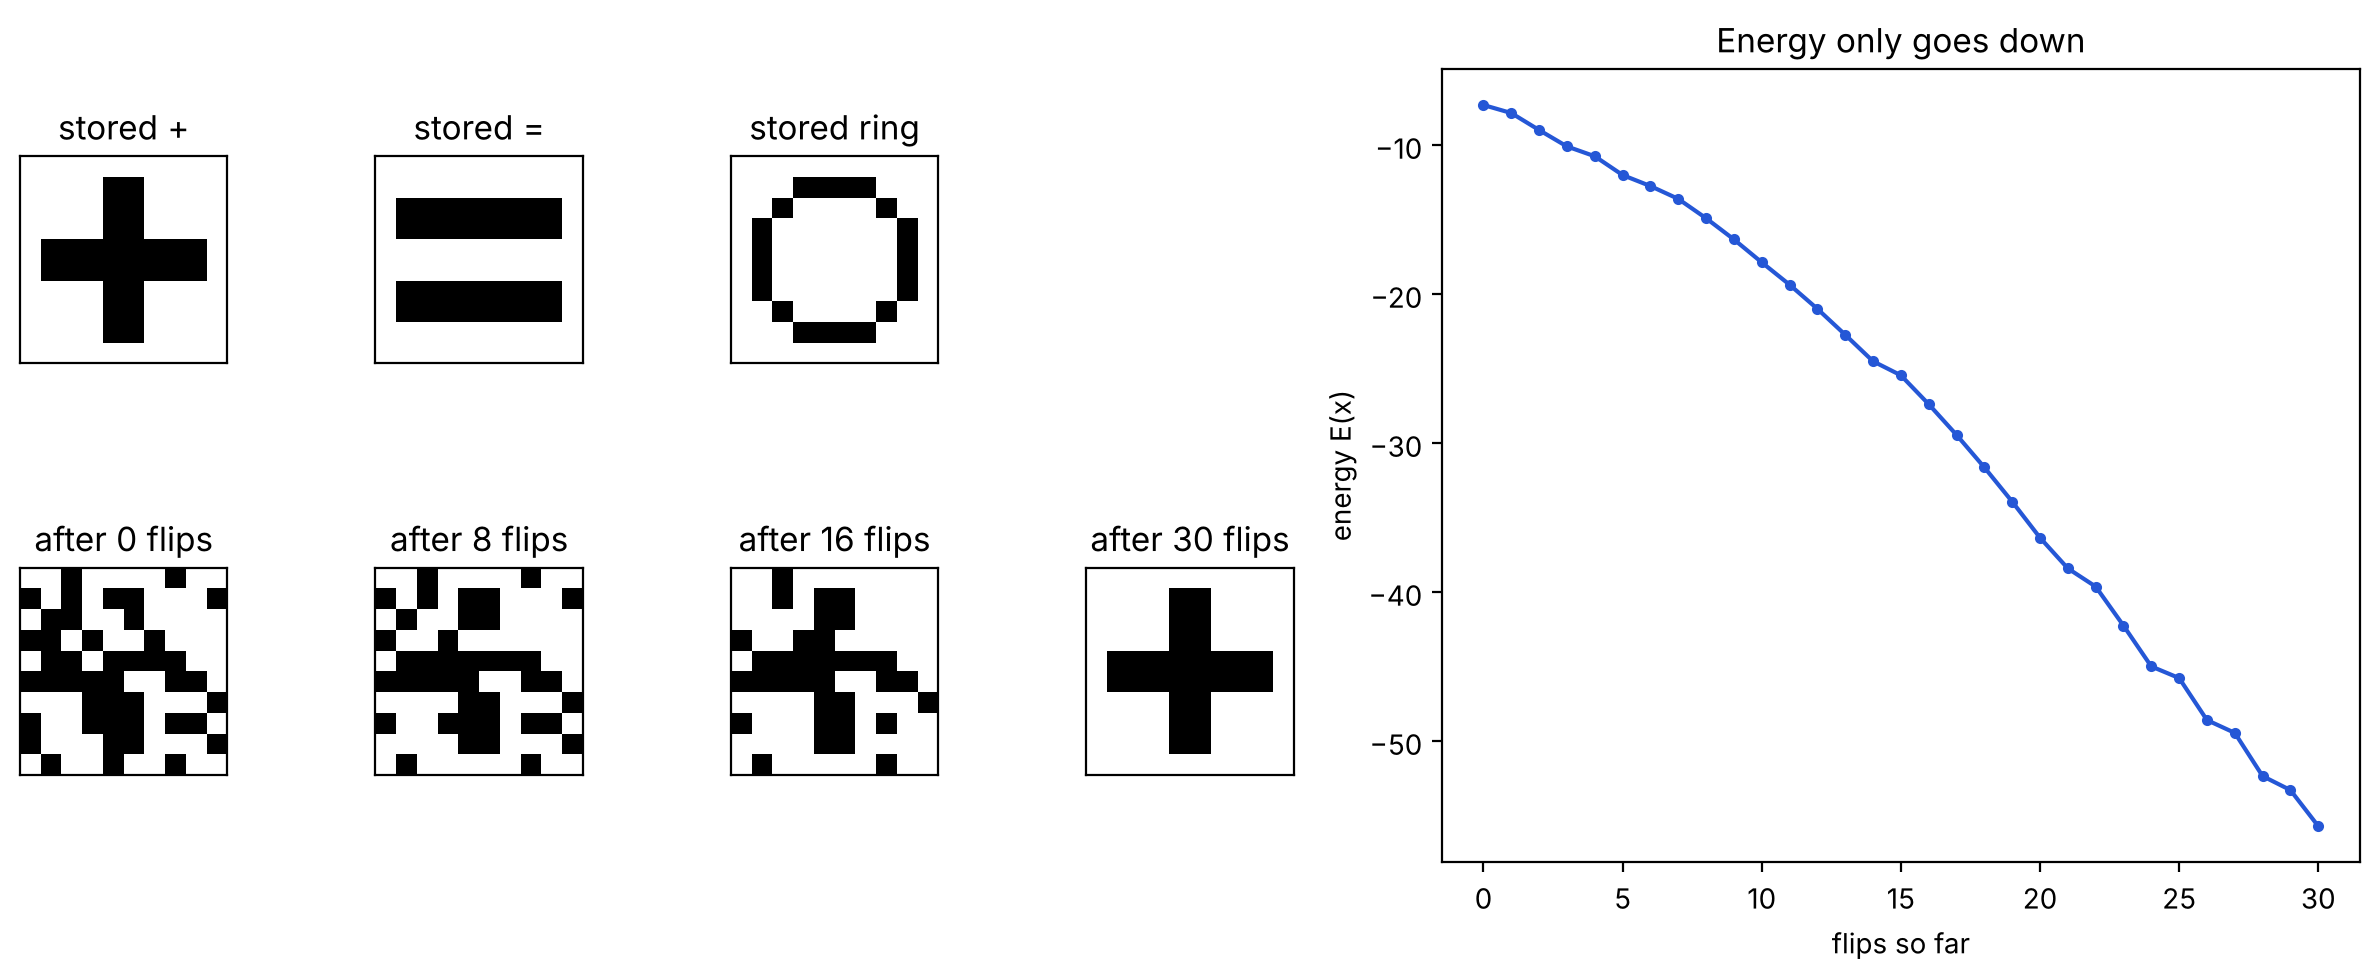

In [7]:
def pattern(rows):
    """+1 where the picture has '#', -1 elsewhere."""
    return np.array([[1 if ch == "#" else -1 for ch in row] for row in rows])


plus = pattern(["..........", "....##....", "....##....", "....##....", ".########.",
                ".########.", "....##....", "....##....", "....##....", ".........."])
equals = pattern(["..........", "..........", ".########.", ".########.", "..........",
                  "..........", ".########.", ".########.", "..........", ".........."])
ring = pattern(["..........", "...####...", "..#....#..", ".#......#.", ".#......#.",
                ".#......#.", ".#......#.", "..#....#..", "...####...", ".........."])

stored = np.array([p.ravel() for p in (plus, equals, ring)])
weights = (stored.T @ stored) / stored.shape[1]    # Hebbian: units that agree in the patterns pull together
np.fill_diagonal(weights, 0)                       # no unit feeds itself


def energy(state):
    """Hopfield energy: low when connected units agree with their weights."""
    return float(-0.5 * state @ weights @ state)


rng = np.random.default_rng(1)
state = plus.ravel().copy()
flipped = rng.choice(100, 30, replace=False)
state[flipped] *= -1
snapshots = {0: state.copy()}
energies = [energy(state)]
changed = True
while changed:                                      # sweep in random order until nothing changes
    changed = False
    for unit in rng.permutation(100):
        new_value = 1 if weights[unit] @ state >= 0 else -1
        if new_value != state[unit]:
            state[unit] = new_value
            changed = True
            energies.append(energy(state))
            n_flips = len(energies) - 1
            if n_flips in (8, 16):
                snapshots[n_flips] = state.copy()
snapshots[len(energies) - 1] = state.copy()

print(f"start energy {energies[0]:.1f}; {len(energies) - 1} flips; end energy {energies[-1]:.1f}")
print("energy after each flip:", [round(e, 1) for e in energies[1:]])
print("back to the stored +:", bool((state == plus.ravel()).all()))

fig = plt.figure(figsize=(12, 5))
grid = fig.add_gridspec(2, 7)
for k, (name, p) in enumerate([("+", plus), ("=", equals), ("ring", ring)]):
    ax = fig.add_subplot(grid[0, k])
    show_image(ax, p, vmin=-1, vmax=1)
    ax.set_title(f"stored {name}")
for k, (n_flips, snap) in enumerate(snapshots.items()):
    ax = fig.add_subplot(grid[1, k])
    show_image(ax, snap, vmin=-1, vmax=1)
    ax.set_title(f"after {n_flips} flips")
ax = fig.add_subplot(grid[:, 4:])
ax.plot(range(len(energies)), energies, color=BLUE, marker="o", markersize=3)
ax.set_title("Energy only goes down")
ax.set_xlabel("flips so far")
ax.set_ylabel("energy E(x)")
fig.tight_layout()
plt.show()

## Stop 8: diffusion

No model is trained here. Noise is added to a hand-drawn 16×16 two with the forward formula x_t = √ᾱ_t · x₀ + √(1 − ᾱ_t) · ε, and the frames are shown in reverse (noise → digit) to illustrate what a trained model's generation looks like.

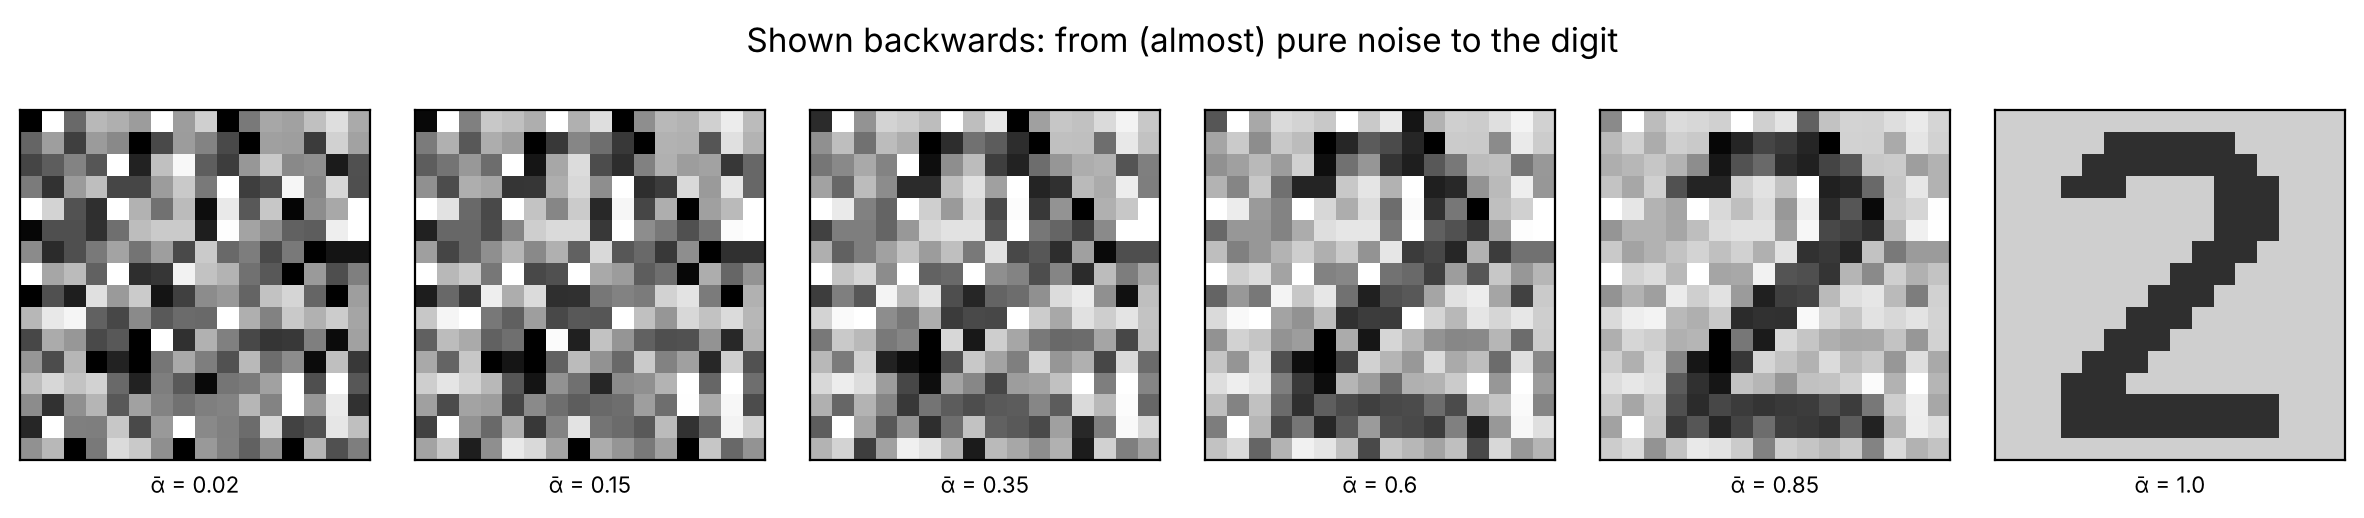

In [8]:
TWO = ["................", ".....######.....", "....########....", "...###....###...", "..........###...",
       "..........###...", ".........###....", "........###.....", ".......###......", "......###.......",
       ".....###........", "....###.........", "...###..........", "...##########...", "...##########...", "................"]
x0 = np.array([[1.0 if ch == "#" else -1.0 for ch in row] for row in TWO])
rng = np.random.default_rng(3)
noise = rng.normal(size=x0.shape)
alpha_bar = [1.0, 0.85, 0.6, 0.35, 0.15, 0.02]          # share of the signal kept at each step
frames = [np.sqrt(a) * x0 + np.sqrt(1 - a) * noise for a in alpha_bar]

fig, axes = plt.subplots(1, len(frames), figsize=(12, 2.4))
for ax, frame, a in zip(axes, frames[::-1], alpha_bar[::-1]):
    show_image(ax, frame, f"ᾱ = {a}", vmin=-1.6, vmax=1.6)
fig.suptitle("Shown backwards: from (almost) pure noise to the digit")
fig.tight_layout()
plt.show()

## Stops 7 and 9: a GAN and a large language model (also "An LLM plays round 1 at scale")

These slides have no code. The next-word bars for “The cat sat on the ___” (mat 0.31, floor 0.18, …) are illustrative numbers, not output from a real model.

## Autoencoder → VAE: the data and the two networks

*Slides: An autoencoder, layer by layer · What the VAE adds to the autoencoder · Autoencoder vs. VAE in PyTorch*

scikit-learn's 8×8 digits, ink scaled to 0–1, split 80/20 (stratified, seed 0): 1,437 training and 360 held-out digits. Both networks are 64 → 128 → 64 → 2 (encoder) and 2 → 64 → 128 → 64 (decoder), ReLU between layers, sigmoid on the 64 output logits ŷ. The VAE's last encoder layer outputs 4 numbers instead of 2: μ and log σ². That is the only difference in parameters (130 more).

In [9]:
SEED = 0
EPOCHS = 20 if QUICK else 600
BATCH = 64
LEARNING_RATE = 1e-3

digits = load_digits()
images = digits.data / 16.0                  # (1797, 64), ink from 0 to 1
labels = digits.target
train_idx, test_idx = train_test_split(np.arange(len(images)), test_size=0.2,
                                       random_state=SEED, stratify=labels)
train_idx = np.sort(train_idx)
test_idx = np.sort(test_idx)
x_train = images[train_idx]
y_train = labels[train_idx]
x_test = images[test_idx]
y_test = labels[test_idx]
print(f"{len(x_train)} training digits, {len(x_test)} held-out digits")

1437 training digits, 360 held-out digits


The model code, shared by the autoencoder and the VAE. The forward pass caches what backprop needs; `loss_and_grads` writes out the gradient of BCE (+ β·KL) by hand, including the reparameterization z = μ + σ ⊙ ε.

In [10]:
def init_layer(rng, n_in, n_out):
    """A Linear layer: Glorot-uniform weights, zero biases."""
    limit = np.sqrt(6.0 / (n_in + n_out))
    return {"W": rng.uniform(-limit, limit, (n_in, n_out)), "b": np.zeros(n_out)}


def sigmoid(y_hat):
    """Logistic sigmoid, written with tanh so large logits cannot overflow."""
    return 0.5 * (1.0 + np.tanh(0.5 * y_hat))


def mlp_forward(layers, x):
    """Linear layers with ReLU between them (none after the last); also return what backprop needs."""
    cache = []
    h = x
    for i, layer in enumerate(layers):
        a = h @ layer["W"] + layer["b"]
        cache.append((h, a))
        if i < len(layers) - 1:
            h = np.maximum(a, 0)
        else:
            h = a
    return h, cache


def mlp_backward(layers, cache, grad_out):
    """Backprop through mlp_forward: gradients for every layer, and for the input."""
    grads = []
    g = grad_out
    for i in reversed(range(len(layers))):
        h_in, a = cache[i]
        if i < len(layers) - 1:
            g = g * (a > 0)                  # ReLU passes gradient only where it was active
        grads.append({"W": h_in.T @ g, "b": g.sum(0)})
        g = g @ layers[i]["W"].T
    grads.reverse()
    return grads, g


def bce_total(p_hat, x):
    """Binary cross-entropy summed over all pixels (and images); p̂ clipped so log never sees 0."""
    p_hat = np.clip(p_hat, 1e-7, 1 - 1e-7)
    return -(x * np.log(p_hat) + (1 - x) * np.log(1 - p_hat)).sum()


class Model:
    """Autoencoder (variational=False) or VAE (variational=True) with a 2-number code; beta weights the KL term."""

    def __init__(self, variational, beta=1.0, seed=SEED):
        rng = np.random.default_rng(seed)
        self.variational = variational
        self.beta = beta
        n_head = 4 if variational else 2     # VAE: μ (2) and log σ² (2) from one Linear 64 → 4, split in half
        self.encoder = [init_layer(rng, 64, 128), init_layer(rng, 128, 64), init_layer(rng, 64, n_head)]
        self.decoder = [init_layer(rng, 2, 64), init_layer(rng, 64, 128), init_layer(rng, 128, 64)]

    def encode(self, x):
        """Autoencoder: the code z. VAE: the code's mean μ."""
        h, _ = mlp_forward(self.encoder, x)
        return h[:, :2]

    def encode_logvar(self, x):
        """VAE only: log σ², the second head."""
        h, _ = mlp_forward(self.encoder, x)
        return h[:, 2:]

    def decode(self, z):
        """p̂ for all 64 pixels from codes z."""
        y_hat, _ = mlp_forward(self.decoder, np.asarray(z, dtype=np.float64))
        return sigmoid(y_hat)

    def loss_and_grads(self, x, rng):
        """Per-image BCE and KL for a batch, and the gradients of BCE + beta·KL for every layer."""
        n = len(x)
        h, enc_cache = mlp_forward(self.encoder, x)
        if self.variational:
            mu = h[:, :2]
            logvar = np.clip(h[:, 2:], -20, 20)
            sigma = np.exp(0.5 * logvar)
            eps = rng.standard_normal(mu.shape)
            z = mu + eps * sigma             # the randomness is in eps, so z is a plain function of μ and σ
        else:
            z = h
        y_hat, dec_cache = mlp_forward(self.decoder, z)
        p_hat = sigmoid(y_hat)
        bce = bce_total(p_hat, x) / n
        kl = 0.0
        if self.variational:
            kl = (-0.5 * (1 + logvar - mu ** 2 - np.exp(logvar)).sum()) / n
        grad_y_hat = (p_hat - x) / n         # sigmoid + BCE: ∂L/∂ŷ = p̂ − x
        dec_grads, grad_z = mlp_backward(self.decoder, dec_cache, grad_y_hat)
        if self.variational:
            grad_mu = grad_z + self.beta * mu / n
            # ∂z/∂log σ² = ½ σ ε, and ∂KL/∂log σ² = ½ (σ² − 1)
            grad_logvar = grad_z * eps * 0.5 * sigma + self.beta * 0.5 * (np.exp(logvar) - 1) / n
            grad_h = np.concatenate([grad_mu, grad_logvar], axis=1)
        else:
            grad_h = grad_z
        enc_grads, _ = mlp_backward(self.encoder, enc_cache, grad_h)
        return bce, kl, enc_grads + dec_grads

    def params(self):
        """All layers, encoder first."""
        return self.encoder + self.decoder

    def n_params(self):
        """Number of weights and biases."""
        return sum(layer["W"].size + layer["b"].size for layer in self.params())

    def evaluate(self, x, seed=123):
        """Per-image averages. AE: BCE. VAE: BCE with one sampled z per image (fixed seed), and KL."""
        if not self.variational:
            return {"bce": bce_total(self.decode(self.encode(x)), x) / len(x)}
        bce, kl, _ = self.loss_and_grads(x, np.random.default_rng(seed))
        return {"bce": bce, "kl": kl}

    def save(self, path):
        """Write every layer's weights to an .npz file."""
        arrays = {}
        for name, layers in (("enc", self.encoder), ("dec", self.decoder)):
            for i, layer in enumerate(layers):
                arrays[f"{name}{i}_W"] = layer["W"]
                arrays[f"{name}{i}_b"] = layer["b"]
        np.savez(path, **arrays)

    def load(self, path):
        """Read weights written by save."""
        saved = np.load(path)
        for name, layers in (("enc", self.encoder), ("dec", self.decoder)):
            for i, layer in enumerate(layers):
                layer["W"] = saved[f"{name}{i}_W"]
                layer["b"] = saved[f"{name}{i}_b"]


ae_n_params = Model(variational=False).n_params()
vae_n_params = Model(variational=True).n_params()
print(f"autoencoder: {ae_n_params:,} parameters; VAE: {vae_n_params:,} ({vae_n_params - ae_n_params} more: the second head)")

autoencoder: 33,474 parameters; VAE: 33,604 (130 more: the second head)


### Training

Minibatch Adam (batch 64, learning rate 10⁻³, 600 epochs, seed 0). The order of random draws (shuffles and ε) is fixed by the seed, so the trained weights, and every number after this, match the slides. Each model is cached after training.

In [11]:
def train(model, epochs=EPOCHS, seed=SEED):
    """Minibatch Adam on the training digits. The rng draws both the shuffles and every ε."""
    rng = np.random.default_rng(seed)
    params = model.params()
    first_moment = [{key: np.zeros_like(value) for key, value in layer.items()} for layer in params]
    second_moment = [{key: np.zeros_like(value) for key, value in layer.items()} for layer in params]
    b1 = 0.9          # Adam's decay rates
    b2 = 0.999
    step = 0
    for _ in range(epochs):
        order = rng.permutation(len(x_train))
        for start in range(0, len(order), BATCH):
            batch = x_train[order[start:start + BATCH]]
            _, _, grads = model.loss_and_grads(batch, rng)
            step += 1
            for layer, grad, m, v in zip(params, grads, first_moment, second_moment):
                for key in layer:
                    m[key] = b1 * m[key] + (1 - b1) * grad[key]
                    v[key] = b2 * v[key] + (1 - b2) * grad[key] ** 2
                    m_hat = m[key] / (1 - b1 ** step)        # bias correction for the zero start
                    v_hat = v[key] / (1 - b2 ** step)
                    layer[key] -= LEARNING_RATE * m_hat / (np.sqrt(v_hat) + 1e-8)


def get_model(name, variational, beta=1.0):
    """Load a cached model, or train it and cache it."""
    model = Model(variational, beta=beta)
    path = WEIGHTS_DIR / f"{name}_{EPOCHS}epochs.npz"
    if path.exists():
        model.load(path)
        print(f"{name}: loaded from {path}")
    else:
        started = time.time()
        train(model)
        model.save(path)
        print(f"{name}: trained {EPOCHS} epochs in {time.time() - started:.0f} s")
    return model


ae = get_model("ae", variational=False)
vae = get_model("vae", variational=True)

ae_scores = ae.evaluate(x_test)
vae_scores = vae.evaluate(x_test)
print(f"\nheld-out, per digit:  autoencoder BCE {ae_scores['bce']:.2f}")
print(f"                      VAE BCE {vae_scores['bce']:.2f} + KL {vae_scores['kl']:.2f}")

ae: trained 600 epochs in 15 s


vae: trained 600 epochs in 16 s

held-out, per digit:  autoencoder BCE 21.19
                      VAE BCE 21.07 + KL 3.16


## An autoencoder, layer by layer · No labels: the target is the input

Our example throughout is the first 3 among the held-out digits. The autoencoder squeezes it to two numbers, the code z, and rebuilds p̂ for all 64 pixels. The loss is the BCE between x and p̂, summed over pixels; here are three of its 64 terms: an inked pixel, the blank pixel the autoencoder inks most, and the first grey pixel. Notice a grey pixel costs 0.69 even when p̂ ≈ x.

autoencoder code for our 3: z = (-10.57, 20.04)

pixel      x      p̂     its term
A inked   1.00   0.95   0.051
B blank   0.00   0.40   0.508
C grey    0.56   0.57   0.685

all 64 terms for our 3: L = 19.59
averaged over the 360 held-out digits: 21.2


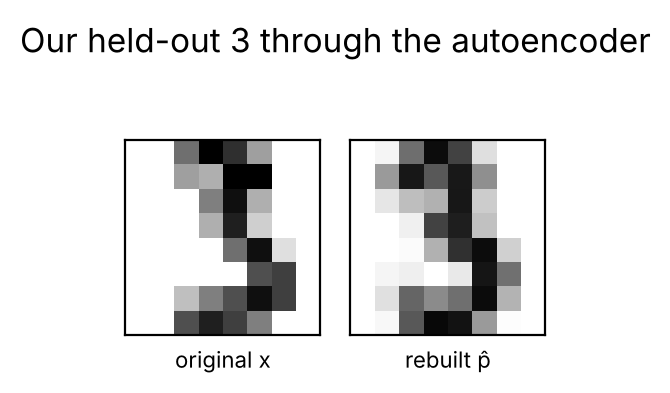

In [12]:
three_index = int(np.where(y_test == 3)[0][0])
x_three = x_test[three_index:three_index + 1]      # shape (1, 64): a batch of one

z_ae = ae.encode(x_three)[0]
p_hat_ae = ae.decode(z_ae[None])[0]
p_clipped = np.clip(p_hat_ae, 1e-7, 1 - 1e-7)
pixel_terms = -(x_three[0] * np.log(p_clipped) + (1 - x_three[0]) * np.log(1 - p_clipped))
print(f"autoencoder code for our 3: z = ({z_ae[0]:.2f}, {z_ae[1]:.2f})")

picks = {"A inked": int(np.argmax(x_three[0] == 1.0)),
         "B blank": int(np.argmax(np.where(x_three[0] == 0.0, p_hat_ae, -1))),
         "C grey": int(np.argmax((x_three[0] > 0.2) & (x_three[0] < 0.8)))}
print("\npixel      x      p̂     its term")
for name, i in picks.items():
    print(f"{name:<9} {x_three[0, i]:.2f}   {p_hat_ae[i]:.2f}   {pixel_terms[i]:.3f}")
print(f"\nall 64 terms for our 3: L = {pixel_terms.sum():.2f}")
print(f"averaged over the {len(x_test)} held-out digits: {ae_scores['bce']:.1f}")

show_row([x_three[0], p_hat_ae], ["original x", "rebuilt p̂"], "Our held-out 3 through the autoencoder")

## An autoencoder compresses, then rebuilds

The first held-out digit of each class, through the two-number bottleneck. Notice which digits come back blurry; the slide shows six of these.

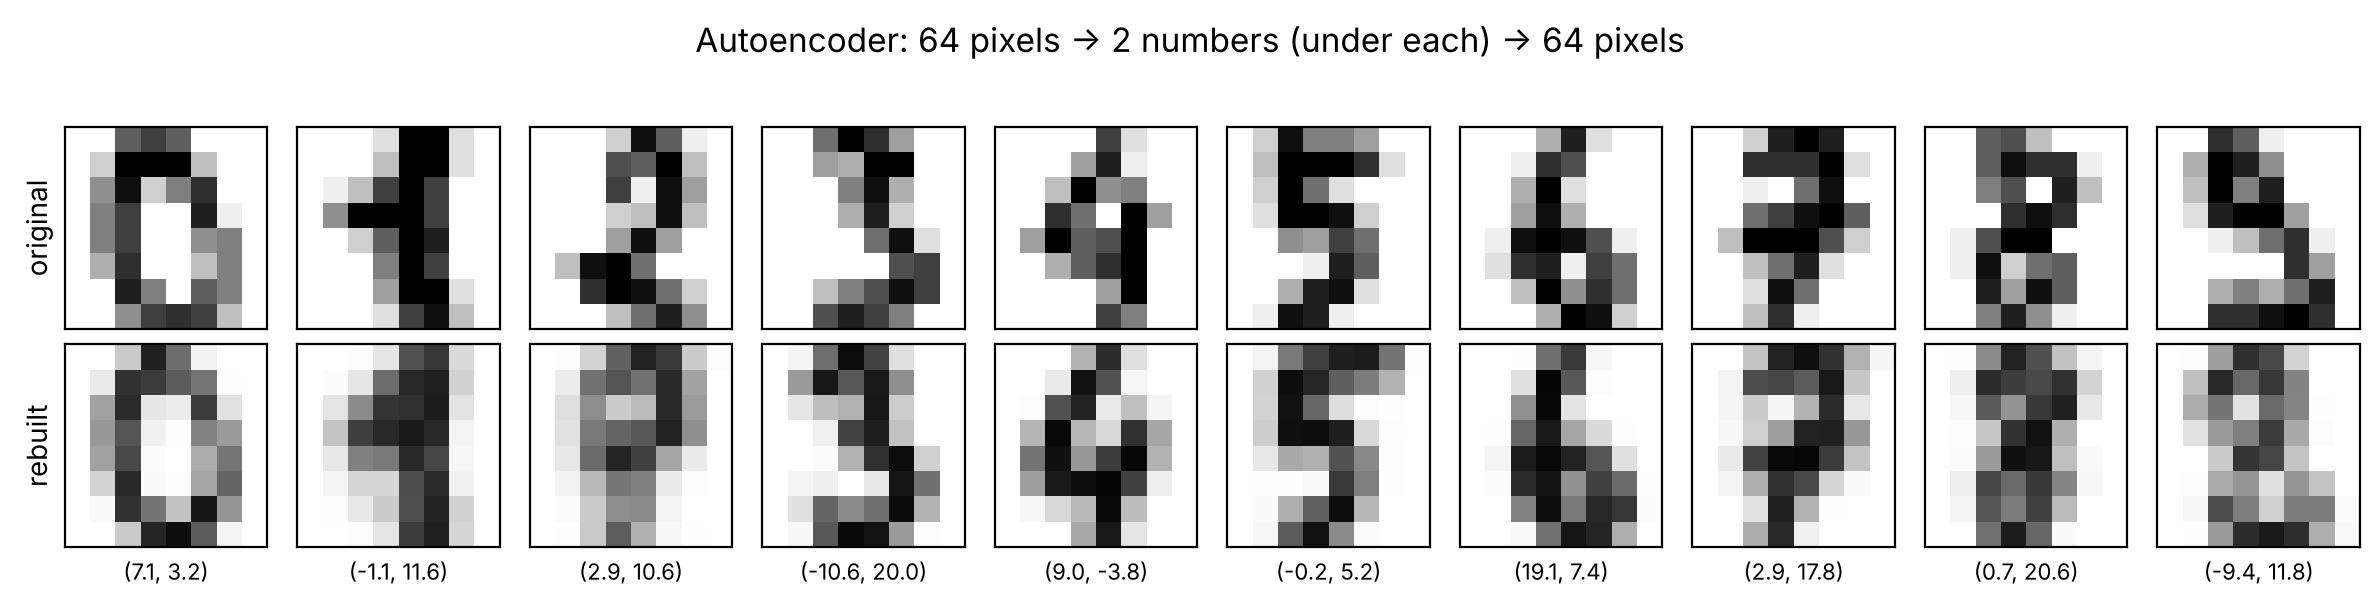

In [13]:
first_of_each = [int(np.where(y_test == digit)[0][0]) for digit in range(10)]
originals = x_test[first_of_each]
codes = ae.encode(originals)
rebuilt = ae.decode(codes)

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for k in range(10):
    show_image(axes[0, k], originals[k])
    show_image(axes[1, k], rebuilt[k], f"({codes[k, 0]:.1f}, {codes[k, 1]:.1f})")
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("rebuilt")
fig.suptitle("Autoencoder: 64 pixels → 2 numbers (under each) → 64 pixels")
fig.tight_layout()
plt.show()

## Maybe random codes give new digits? · Where the autoencoder put its codes

Keep only the decoder and feed it ten codes drawn from N(0, I). Then plot where the encoder actually put the 1,437 training codes. Notice the codes span tens of units, while N(0, I) draws land in one small region near (0, 0).

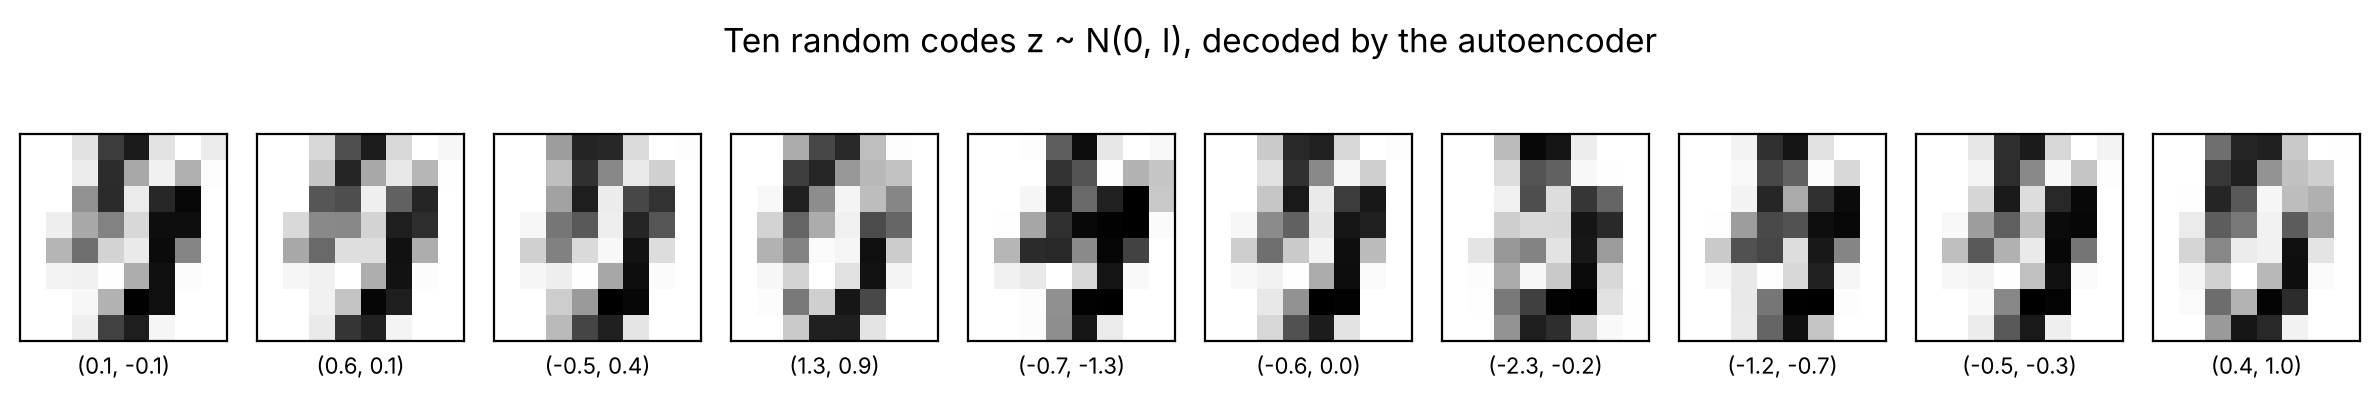

autoencoder codes run from -24 to 23 across and -8 to 32 up


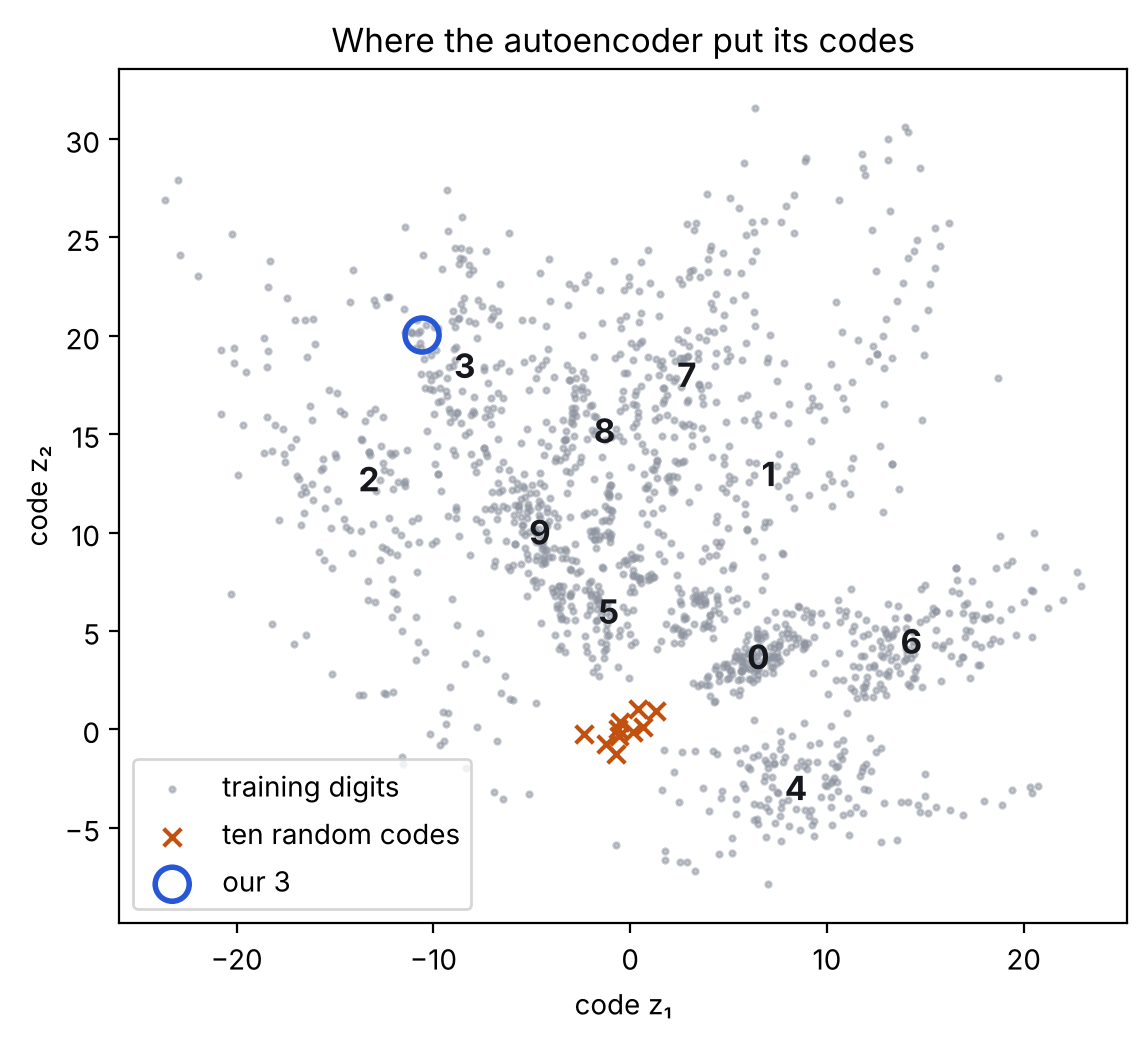

In [14]:
rng = np.random.default_rng(SEED)
z_random = rng.standard_normal((10, 2))         # the same ten codes are reused for the VAE below
show_row(ae.decode(z_random), [f"({z[0]:.1f}, {z[1]:.1f})" for z in z_random],
         "Ten random codes z ~ N(0, I), decoded by the autoencoder")

ae_codes = ae.encode(x_train)
low = ae_codes.min(0)
high = ae_codes.max(0)
print(f"autoencoder codes run from {low[0]:.0f} to {high[0]:.0f} across and {low[1]:.0f} to {high[1]:.0f} up")


def plot_codes(ax, codes, codes_labels, title, label_digits=True):
    """Training codes in grey, each digit's label at the middle of its codes, random codes as orange crosses."""
    ax.scatter(codes[:, 0], codes[:, 1], s=4, color=GREY, alpha=0.5, label="training digits")
    if label_digits:
        for digit in range(10):
            middle = np.median(codes[codes_labels == digit], axis=0)
            ax.text(middle[0], middle[1], str(digit), color=INK, fontsize=12, weight="bold", ha="center", va="center")
    ax.scatter(z_random[:, 0], z_random[:, 1], marker="x", s=40, color=ORANGE, label="ten random codes")
    ax.set_title(title)
    ax.set_xlabel("code z₁")
    ax.set_ylabel("code z₂")
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(6.5, 6.5))
plot_codes(ax, ae_codes, y_train, "Where the autoencoder put its codes")
ax.scatter(*z_ae, s=150, facecolor="none", edgecolor=BLUE, linewidth=2, label="our 3")
ax.legend(loc="lower left")
plt.show()

## A VAE fills in the gaps

The VAE's training codes (its means μ) on the same axes as the autoencoder's, with rings at radius 1, 2 and 3, and the same ten random codes decoded by the VAE decoder. Notice the VAE's codes are pulled into one cloud where N(0, I) samples land. The first six decoded codes are also the ones on the Stop 6 (VAE) tour slide.

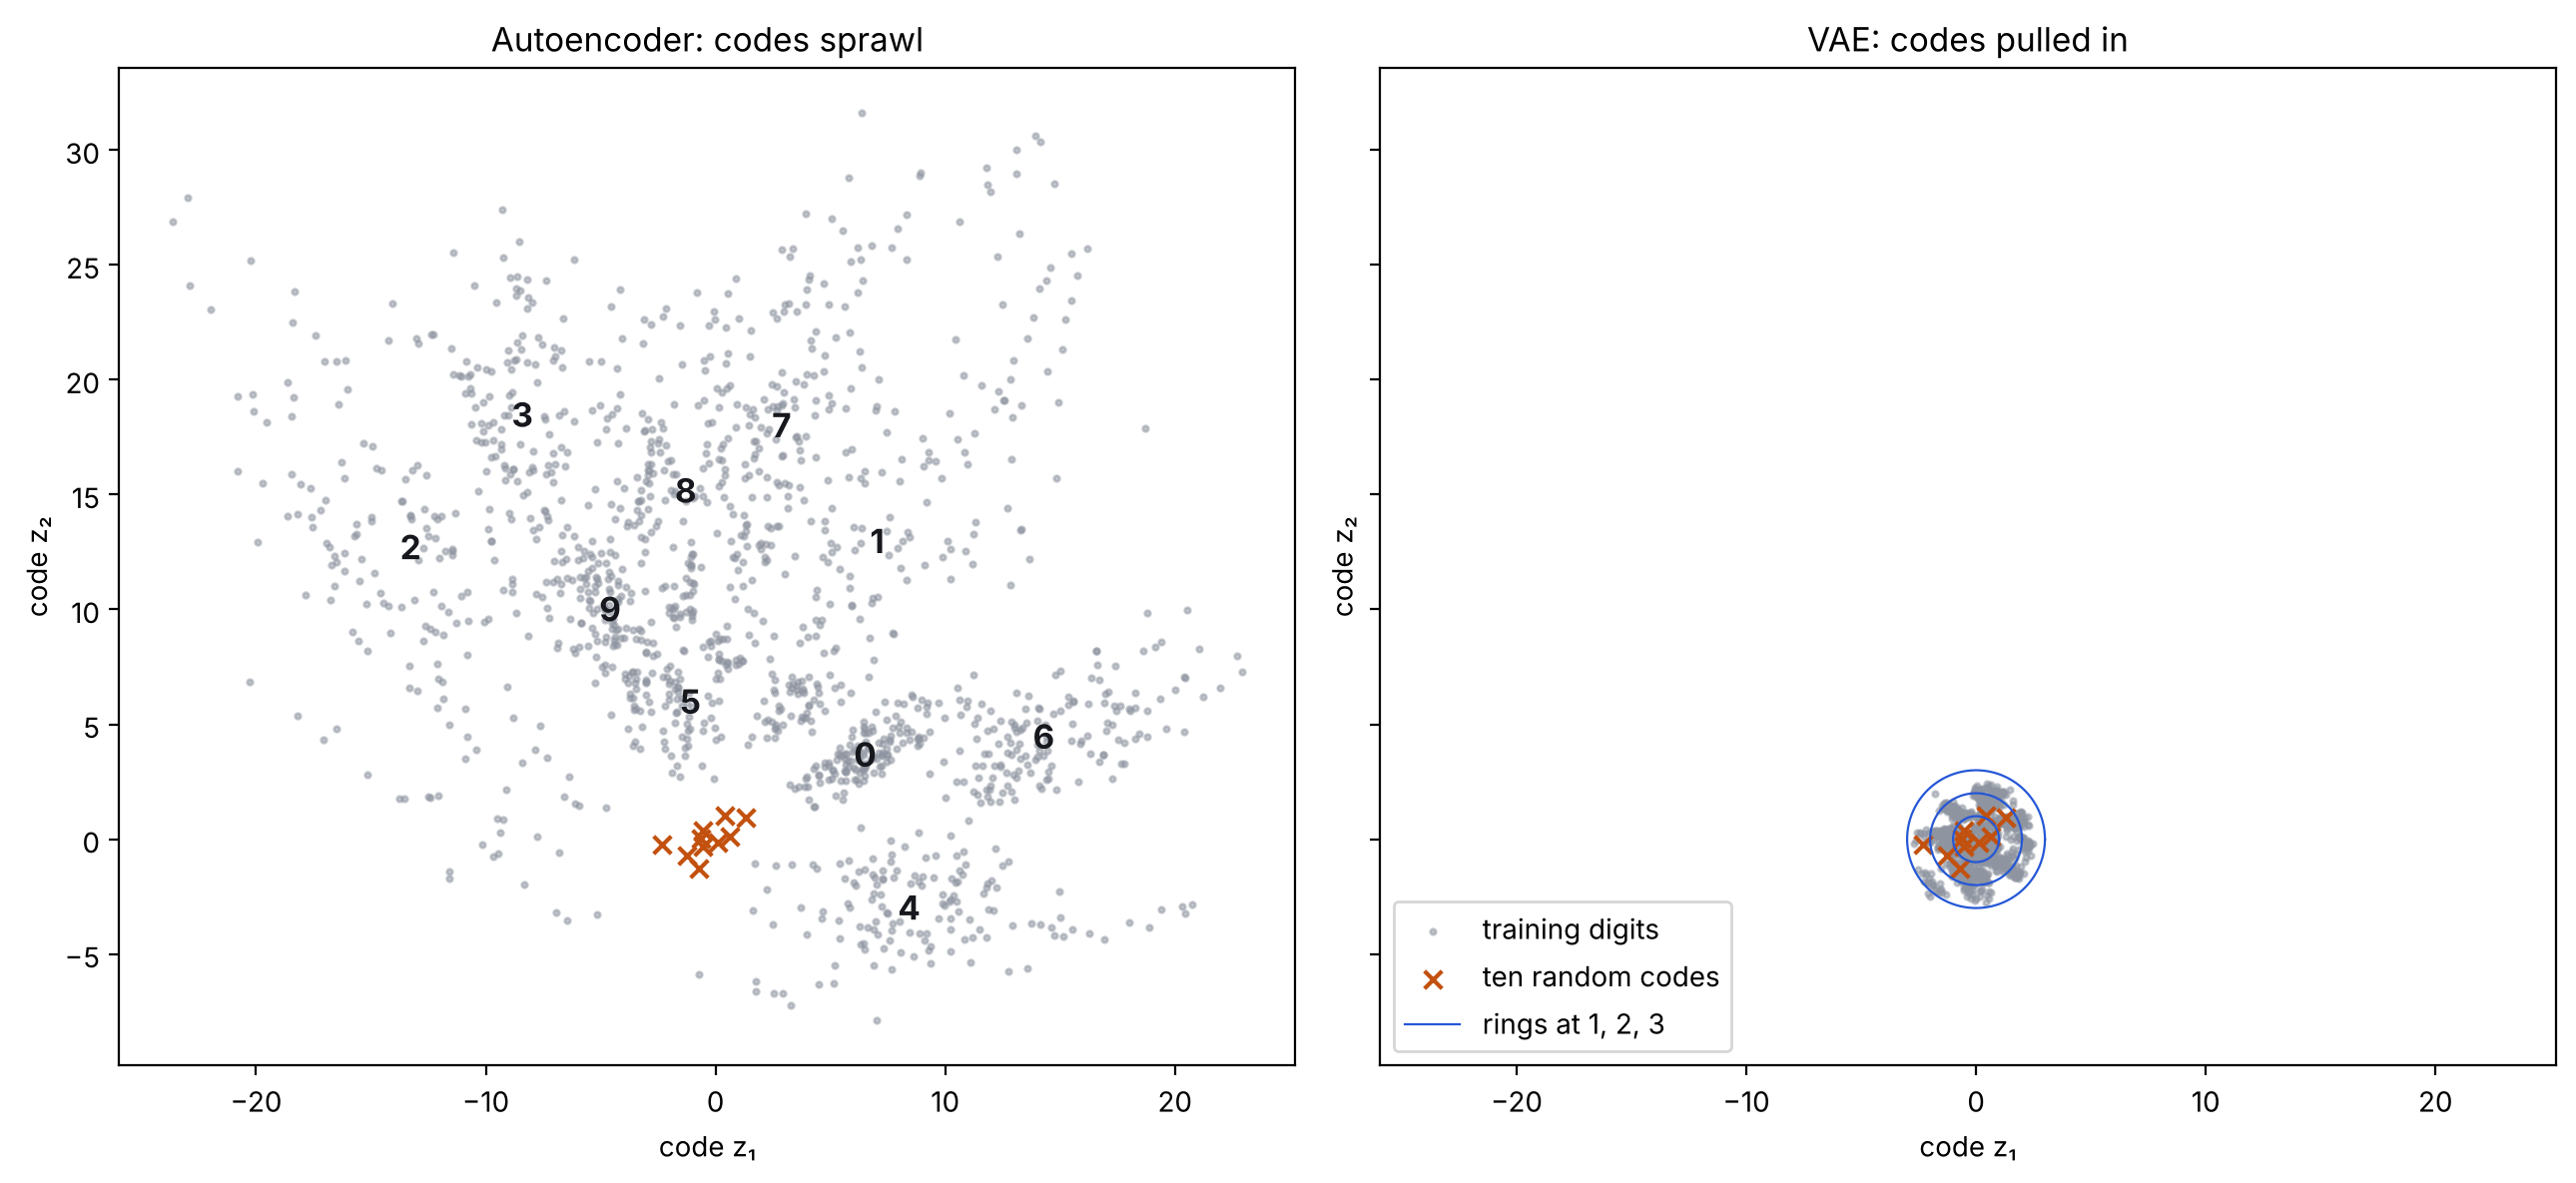

VAE means run from -2.7 to 2.5 across and -2.8 to 2.4 up


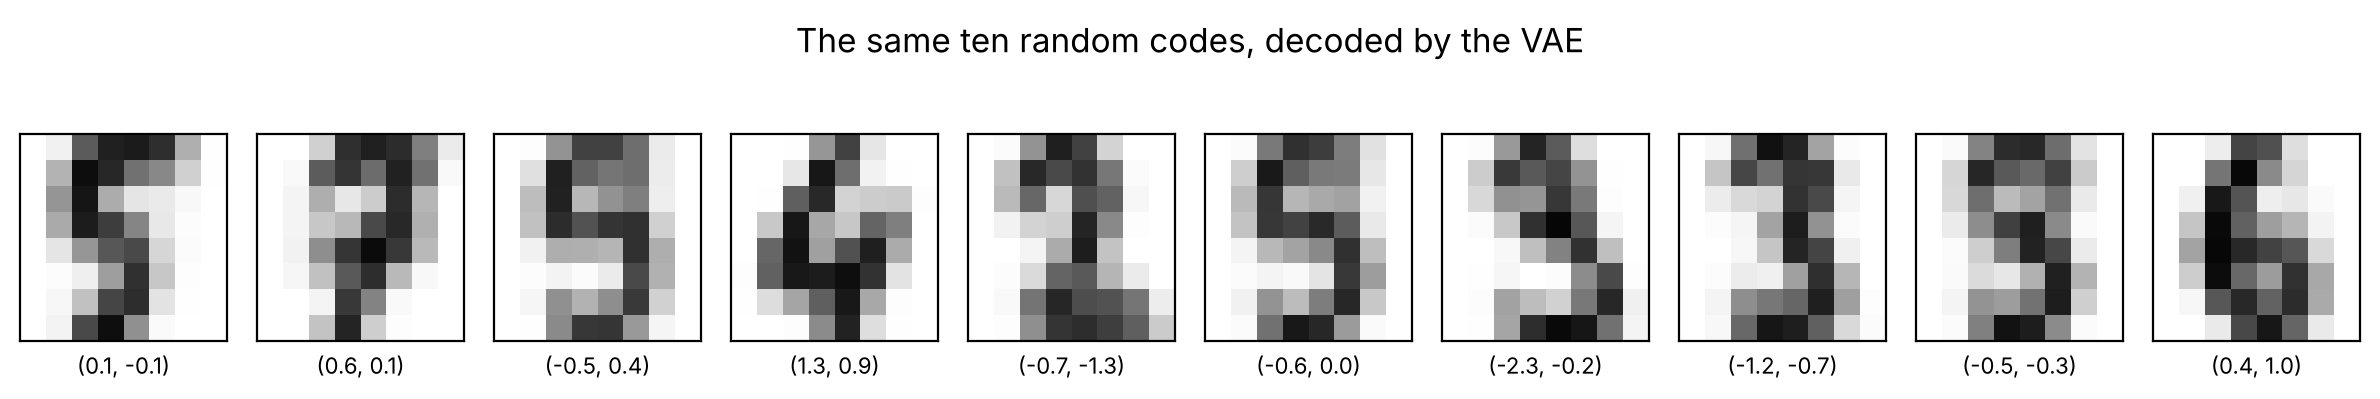

In [15]:
vae_mu = vae.encode(x_train)
angles = np.linspace(0, 2 * np.pi, 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharex=True, sharey=True)
plot_codes(axes[0], ae_codes, y_train, "Autoencoder: codes sprawl")
plot_codes(axes[1], vae_mu, y_train, "VAE: codes pulled in", label_digits=False)   # too crowded to label
for radius in (1, 2, 3):
    axes[1].plot(radius * np.cos(angles), radius * np.sin(angles), color=BLUE, linewidth=0.8,
                 label="rings at 1, 2, 3" if radius == 1 else None)
axes[1].legend(loc="lower left")
fig.tight_layout()
plt.show()

print(f"VAE means run from {vae_mu[:, 0].min():.1f} to {vae_mu[:, 0].max():.1f} across "
      f"and {vae_mu[:, 1].min():.1f} to {vae_mu[:, 1].max():.1f} up")
show_row(vae.decode(z_random), [f"({z[0]:.1f}, {z[1]:.1f})" for z in z_random],
         "The same ten random codes, decoded by the VAE")

## What the VAE adds · The encoder outputs a distribution, q̂(z | x)

For our 3 the encoder's two heads give μ and log σ²; σ = e^(½ log σ²) is always positive. q̂(z | x) = N(μ, σ²) is a small cloud, not a point. The plot zooms in on the VAE's code space.

*Note:* the slide halves the rounded log σ² (−2.053 / 2 = −1.026, −2.981 / 2 = −1.490); the exact exponents print as −1.027 and −1.491. σ is the same either way.

μ      = (-1.415, -0.463)
log σ² = (-2.053, -2.981)
σ1 = e^(-1.027) = 0.358
σ2 = e^(-1.491) = 0.225
(the autoencoder gave one point: (-10.57, 20.04))


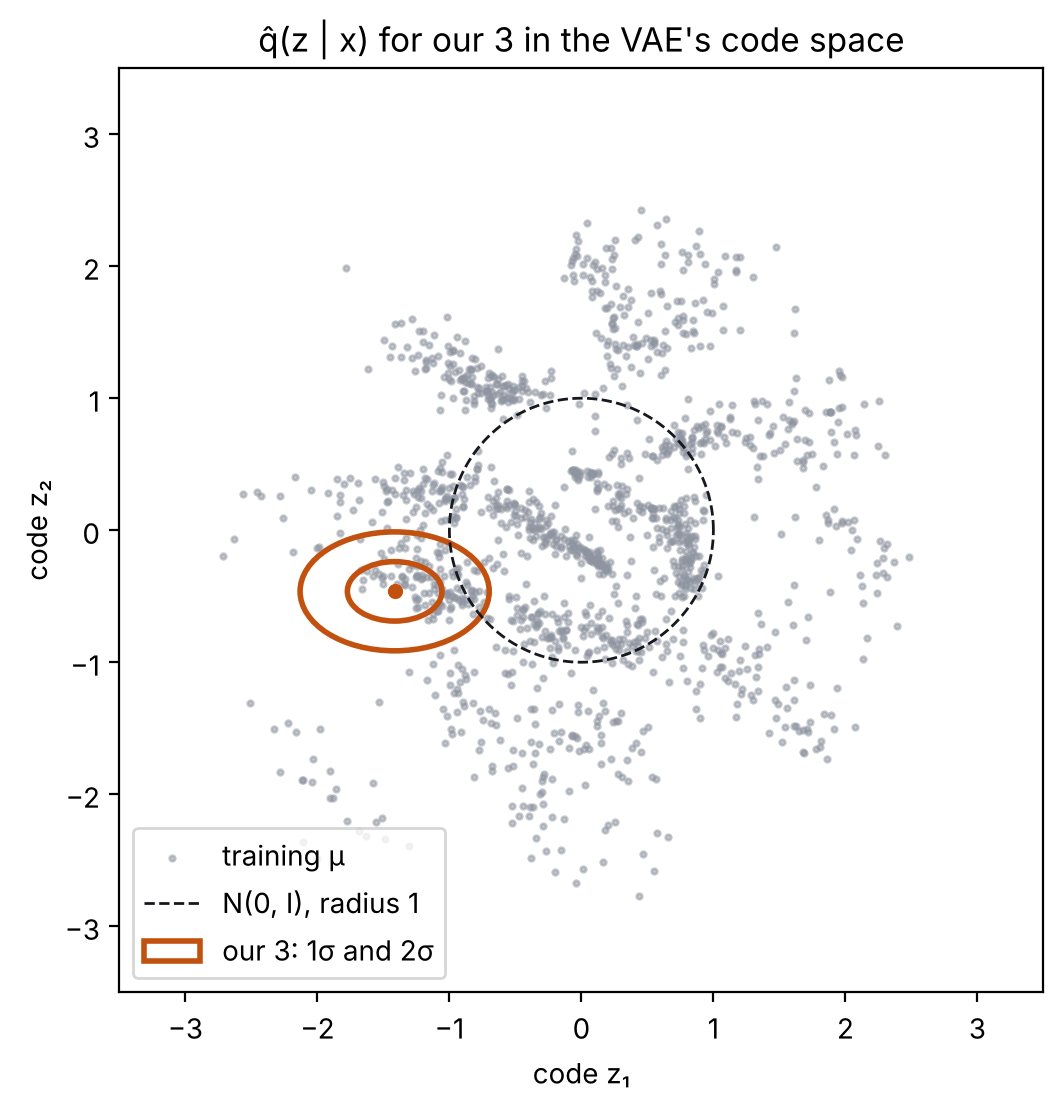

In [16]:
mu = vae.encode(x_three)[0]
logvar = vae.encode_logvar(x_three)[0]
sigma = np.exp(0.5 * logvar)
print(f"μ      = ({mu[0]:.3f}, {mu[1]:.3f})")
print(f"log σ² = ({logvar[0]:.3f}, {logvar[1]:.3f})")
for j in range(2):
    print(f"σ{j + 1} = e^({0.5 * logvar[j]:.3f}) = {sigma[j]:.3f}")
print(f"(the autoencoder gave one point: ({z_ae[0]:.2f}, {z_ae[1]:.2f}))")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(vae_mu[:, 0], vae_mu[:, 1], s=4, color=GREY, alpha=0.5, label="training μ")
ax.plot(np.cos(angles), np.sin(angles), color=INK, linestyle="--", linewidth=1, label="N(0, I), radius 1")
for n_sigma in (1, 2):
    ax.add_patch(Ellipse(mu, 2 * n_sigma * sigma[0], 2 * n_sigma * sigma[1], facecolor="none",
                         edgecolor=ORANGE, linewidth=2, label="our 3: 1σ and 2σ" if n_sigma == 1 else None))
ax.scatter(*mu, color=ORANGE, s=20)
ax.set_xlim(-3.5, 3.5)
ax.set_ylim(-3.5, 3.5)
ax.set_aspect("equal")
ax.set_title("q̂(z | x) for our 3 in the VAE's code space")
ax.set_xlabel("code z₁")
ax.set_ylabel("code z₂")
ax.legend(loc="lower left")
plt.show()

## Sampling a code: z = μ + σ ⊙ ε

Three draws of ε ~ N(0, I) (seed 5), each moved by μ and stretched by σ, decoded, and scored with the BCE. Same μ and σ, three slightly different 3s.

draw   ε                    σ ⊙ ε                z = μ + σ ⊙ ε        BCE
1      (-0.802, -1.324)   (-0.287, -0.298)   (-1.702, -0.761)   17.99
2      (-0.248, 0.420)   (-0.089, 0.095)   (-1.504, -0.368)   18.21
3      (1.136, 0.110)   (0.407, 0.025)   (-1.008, -0.438)   19.15

draw 1 by hand: z₁ = -1.415 + 0.358 × (-0.802) = -1.702
                z₂ = -0.463 + 0.225 × (-1.324) = -0.761


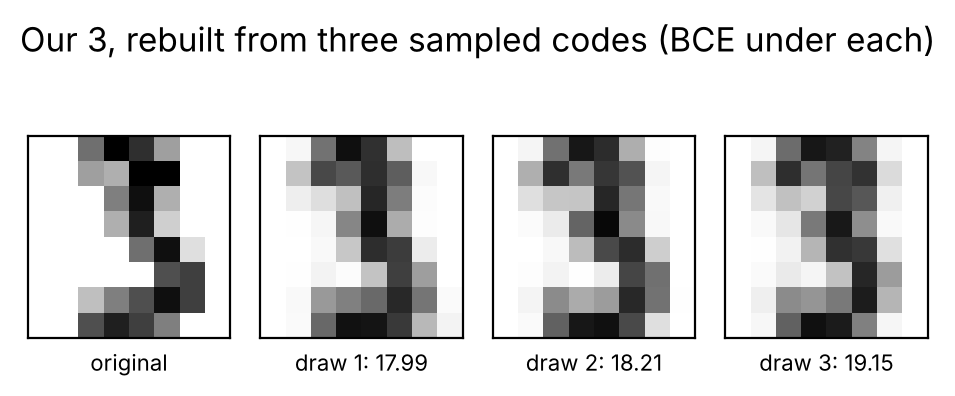

In [17]:
rng = np.random.default_rng(5)
eps = rng.standard_normal((3, 2))
z_draws = mu + sigma * eps
p_hat_draws = vae.decode(z_draws)
draw_bce = [bce_total(p_hat_draws[k], x_three[0]) for k in range(3)]

print("draw   ε                    σ ⊙ ε                z = μ + σ ⊙ ε        BCE")
for k in range(3):
    spread = sigma * eps[k]
    print(f"{k + 1}      ({eps[k, 0]:.3f}, {eps[k, 1]:.3f})   ({spread[0]:.3f}, {spread[1]:.3f})   "
          f"({z_draws[k, 0]:.3f}, {z_draws[k, 1]:.3f})   {draw_bce[k]:.2f}")
print(f"\ndraw 1 by hand: z₁ = {mu[0]:.3f} + {sigma[0]:.3f} × ({eps[0, 0]:.3f}) = {z_draws[0, 0]:.3f}")
print(f"                z₂ = {mu[1]:.3f} + {sigma[1]:.3f} × ({eps[0, 1]:.3f}) = {z_draws[0, 1]:.3f}")

show_row([x_three[0]] + list(p_hat_draws), ["original"] + [f"draw {k + 1}: {b:.2f}" for k, b in enumerate(draw_bce)],
         "Our 3, rebuilt from three sampled codes (BCE under each)")

## The VAE loss: the autoencoder's, plus one term

L = BCE(x, p̂) + KL(q̂(z | x) ‖ N(0, I)), with p̂ decoded from draw 1. The KL term has a closed form, ½ Σⱼ (μⱼ² + σⱼ² − log σⱼ² − 1), computed here dimension by dimension.

*Note:* the slide's μ₁² = 2.002 squares the rounded μ₁ = −1.415; the exact μ₁² is 2.001. The KL terms (1.591, 1.123, total 2.715) are unaffected.

In [18]:
kl_per_dim = 0.5 * (mu ** 2 + sigma ** 2 - logvar - 1)
print(f"BCE (draw 1) = {draw_bce[0]:.2f}   (the autoencoder scored {pixel_terms.sum():.2f} on this 3)")
for j in range(2):
    print(f"KL, j = {j + 1}: ½({mu[j] ** 2:.3f} + {sigma[j] ** 2:.3f} + {-logvar[j]:.3f} − 1) = {kl_per_dim[j]:.3f}")
print(f"KL = {kl_per_dim.sum():.3f}")
print(f"L = {draw_bce[0]:.2f} + {kl_per_dim.sum():.2f} = {draw_bce[0] + kl_per_dim.sum():.2f}")
print(f"held-out average: {vae_scores['bce']:.1f} + {vae_scores['kl']:.1f}")

BCE (draw 1) = 17.99   (the autoencoder scored 19.59 on this 3)
KL, j = 1: ½(2.001 + 0.128 + 2.053 − 1) = 1.591
KL, j = 2: ½(0.214 + 0.051 + 2.981 − 1) = 1.123
KL = 2.715
L = 17.99 + 2.71 = 20.70
held-out average: 21.1 + 3.2


## What if we drop the KL term? · How hard to pull: the KL weight β

Train the same VAE with L = BCE + β·KL for β ∈ {0, 0.1, 1, 2, 4} (β = 0 is the "drop the KL term" question; β = 1 is the VAE above). Each row is judged on 1,000 random codes z ~ N(0, I): a logistic-regression digit classifier is "sure" when it gives one digit ≥ 0.9, and "kinds" counts the different digits among the sure ones. Notice β = 0 sprawls like the autoencoder (σ → 0) and β = 4 collapses (every code is N(0, I), KL = 0, and the code says nothing).

judge: logistic regression, held-out accuracy 96.7%



vae_beta0: trained 600 epochs in 16 s


vae_beta0.1: trained 600 epochs in 16 s


vae_beta2: trained 600 epochs in 16 s


vae_beta4: trained 600 epochs in 16 s

   β    BCE      KL  max|μ|  avg σ  sure · kinds
   0   20.9  135.67    43.3   0.00  67% · 2
 0.1   20.8    6.56     3.2   0.05  51% · 10
   1   21.1    3.16     2.8   0.22  55% · 10
   2   23.4    1.57     2.3   0.46  25% · 6
   4   27.2    0.00     0.0   1.00  0% · 0


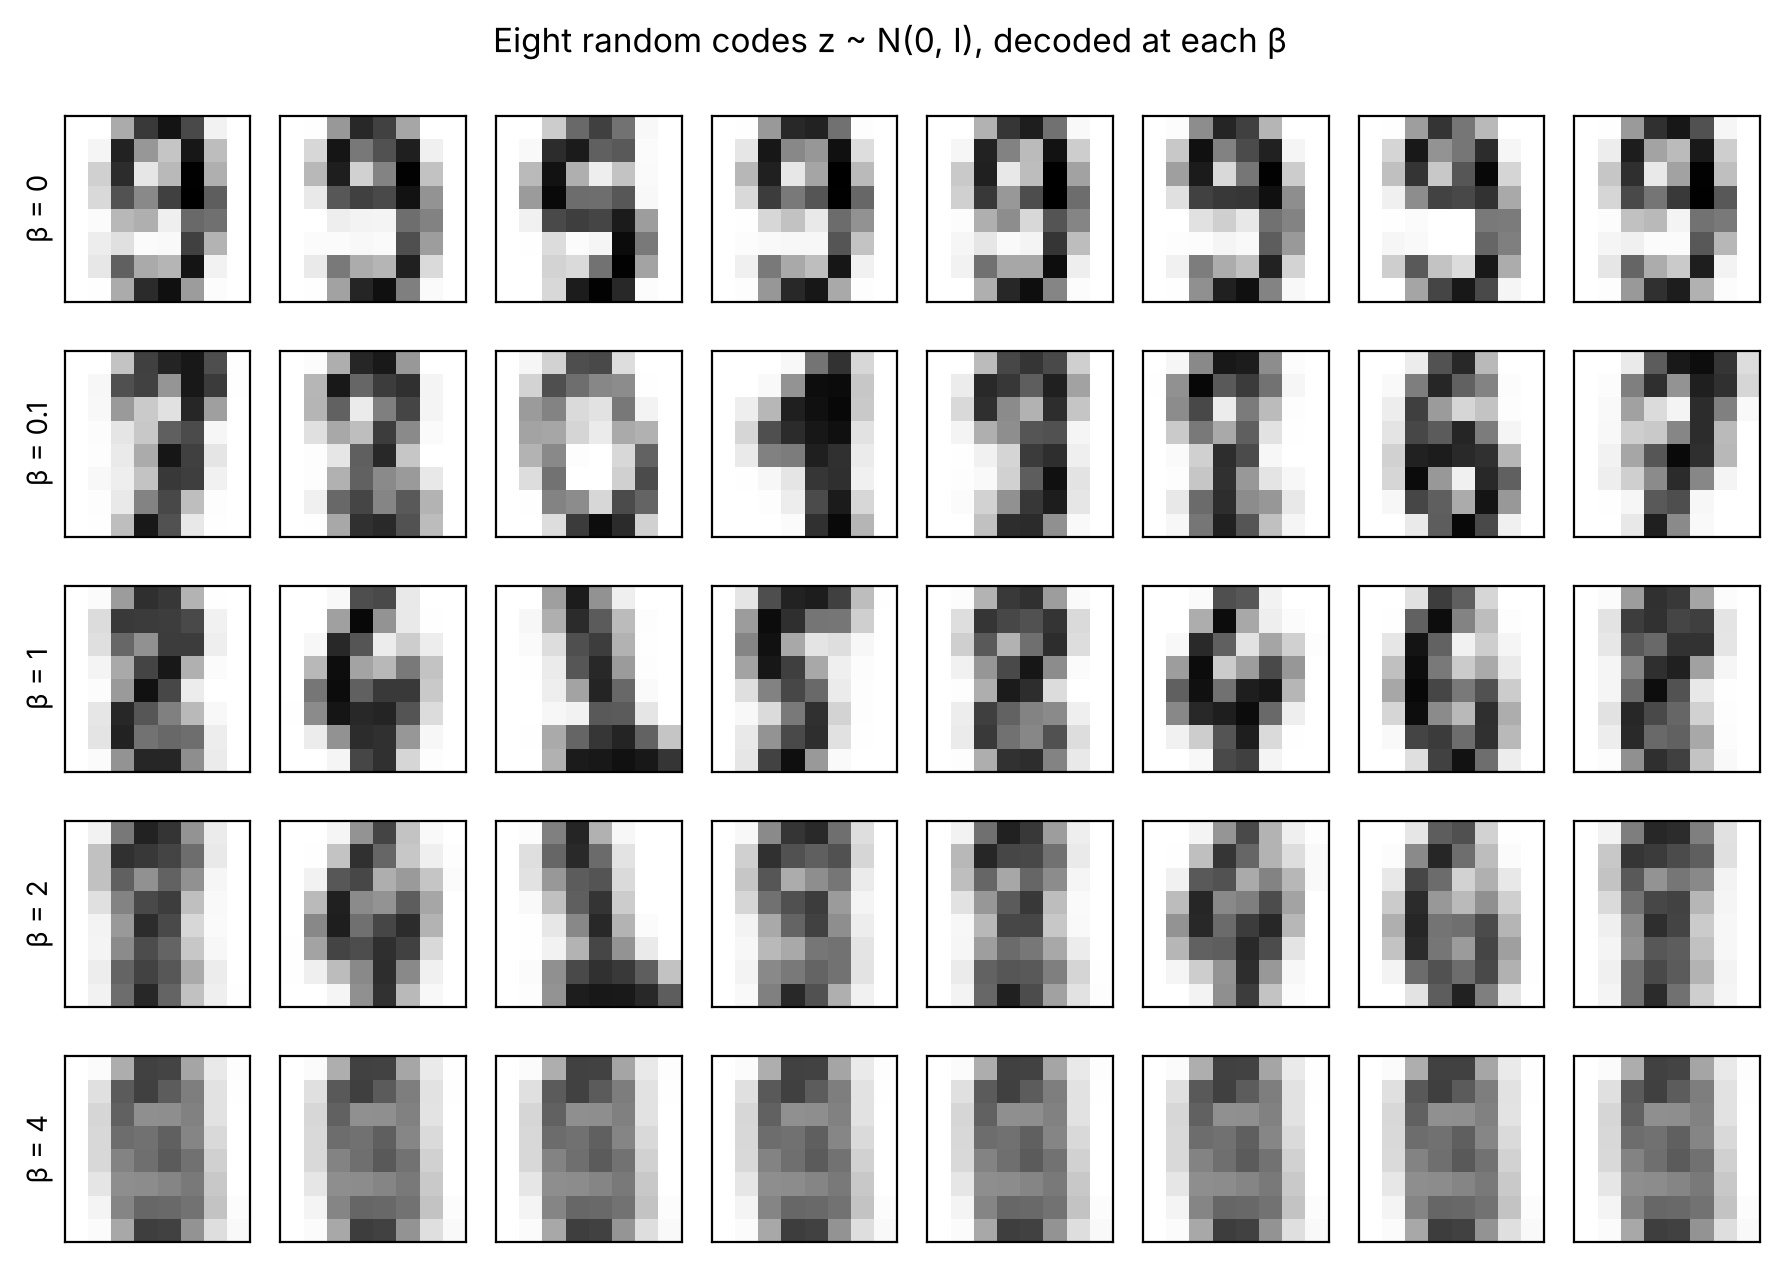

In [19]:
BETAS = [0.0, 0.1, 1.0, 2.0, 4.0]

judge = LogisticRegression(max_iter=5000, C=1.0).fit(x_train, y_train)
print(f"judge: logistic regression, held-out accuracy {judge.score(x_test, y_test):.1%}\n")

z_judged = np.random.default_rng(42).standard_normal((1000, 2))
z_shown = z_judged[:8]                       # the eight samples drawn on the slide

beta_models = {}
for beta in BETAS:
    if beta == 1.0:
        beta_models[beta] = vae              # the standard VAE, already trained
    else:
        beta_models[beta] = get_model(f"vae_beta{beta:g}", variational=True, beta=beta)

print(f"\n{'β':>4}  {'BCE':>5}  {'KL':>6}  {'max|μ|':>6}  {'avg σ':>5}  sure · kinds")
for beta, model in beta_models.items():
    scores = model.evaluate(x_test)
    train_mu = model.encode(x_train)
    train_sigma = np.exp(0.5 * model.encode_logvar(x_train))
    probabilities = judge.predict_proba(model.decode(z_judged))
    sure = probabilities.max(1) >= 0.9
    kinds = len(set(probabilities.argmax(1)[sure]))
    print(f"{beta:>4g}  {scores['bce']:>5.1f}  {scores['kl']:>6.2f}  {np.abs(train_mu).max():>6.1f}  "
          f"{train_sigma.mean():>5.2f}  {sure.mean():.0%} · {kinds}")

fig, axes = plt.subplots(len(BETAS), 8, figsize=(9, 6.5))
for row, (beta, model) in enumerate(beta_models.items()):
    for k, image in enumerate(model.decode(z_shown)):
        show_image(axes[row, k], image)
    axes[row, 0].set_ylabel(f"β = {beta:g}")
fig.suptitle("Eight random codes z ~ N(0, I), decoded at each β")
fig.tight_layout()
plt.show()

## Backprop through a random draw

For our 3 and draw 1 (n = 1): backprop through the decoder gives ∂L/∂z. Because z = μ + σ ⊙ ε with ε drawn on the side, ∂z/∂μ = 1 and ∂z/∂σ = ε, so the gradient reaches the encoder's outputs; the KL term adds μ and σ − 1/σ.

In [20]:
y_hat, decoder_cache = mlp_forward(vae.decoder, z_draws[:1])
p_hat = sigmoid(y_hat)
_, dL_dz = mlp_backward(vae.decoder, decoder_cache, p_hat - x_three)   # sigmoid + BCE: ∂L/∂ŷ = p̂ − x
dL_dz = dL_dz[0]

dL_dmu_rebuild = dL_dz * 1                 # ∂z/∂μ = 1
dL_dsigma_rebuild = dL_dz * eps[0]          # ∂z/∂σ = ε
dKL_dmu = mu
dKL_dsigma = sigma - 1 / sigma


def pair(v):
    """Format a 2-vector as on the slides."""
    return f"({v[0]:.3f}, {v[1]:.3f})"


print("∂L/∂z =", pair(dL_dz), f"  (ε = ({eps[0, 0]:.2f}, {eps[0, 1]:.2f}))")
print("∂L/∂μ = ∂L/∂z · 1 + μ =", pair(dL_dmu_rebuild), "+", pair(dKL_dmu), "=", pair(dL_dmu_rebuild + dKL_dmu))
print("∂L/∂σ = ∂L/∂z ⊙ ε + (σ − 1/σ) =", pair(dL_dsigma_rebuild), "+", pair(dKL_dsigma), "=",
      pair(dL_dsigma_rebuild + dKL_dsigma))

∂L/∂z = (-0.041, -3.472)   (ε = (-0.80, -1.32))
∂L/∂μ = ∂L/∂z · 1 + μ = (-0.041, -3.472) + (-1.415, -0.463) = (-1.456, -3.935)
∂L/∂σ = ∂L/∂z ⊙ ε + (σ − 1/σ) = (0.033, 4.598) + (-2.434, -4.215) = (-2.400, 0.383)


## Autoencoder vs. VAE in PyTorch

No code here: open the two networks in Torch Canvas ([autoencoder](https://jessetnroberts.github.io/torch-canvas/?open=autoencoder_digits), [VAE](https://jessetnroberts.github.io/torch-canvas/?open=vae_digits)) to see the equivalent PyTorch. The slide's PyTorch uses two Linear 64 → 2 heads where the NumPy code above uses one Linear 64 → 4 split in half; they are the same layer.

## Walking the map

Decode a 12×12 grid of codes placed at standard-normal quantiles 0.05 … 0.95 on each axis (±1.645, which the slide rounds to ±1.65 and the tick labels below to ±1.64), as in Kingma & Welling (2013), fig. 4. Notice neighbours look alike and there are no holes.

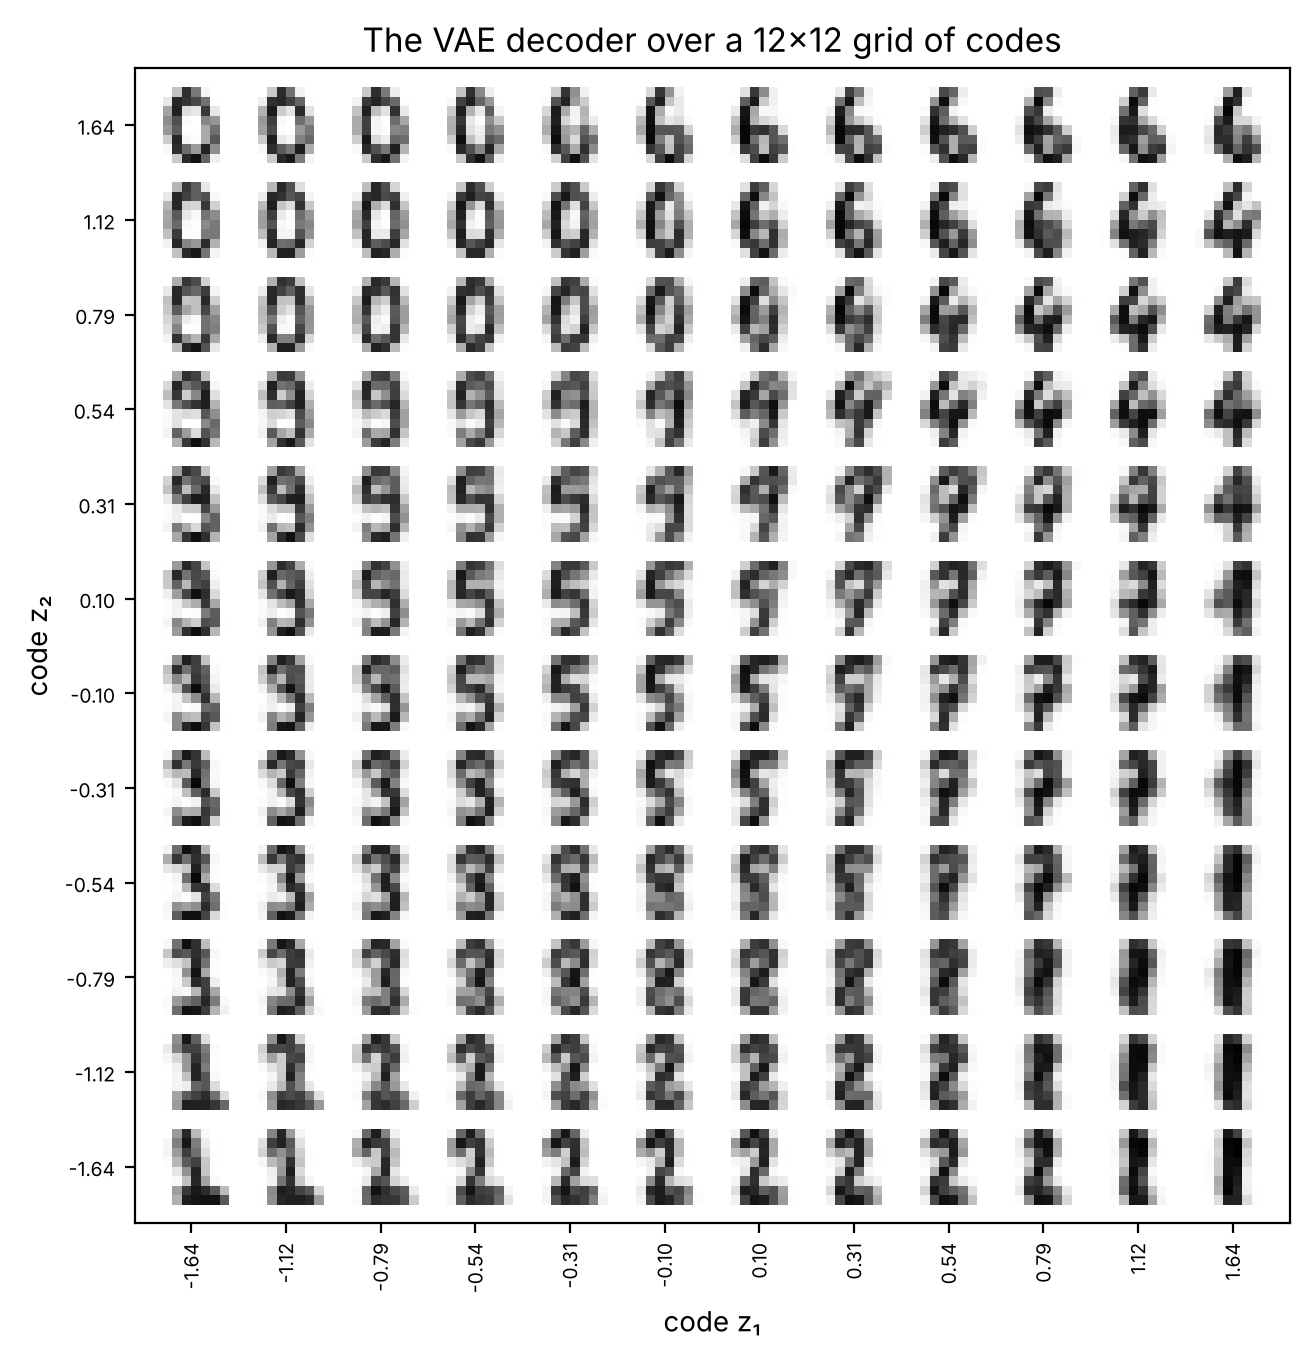

In [21]:
N_SIDE = 12
axis_values = norm.ppf(np.linspace(0.05, 0.95, N_SIDE))
tile = 8
gap = 2
mosaic = np.zeros((N_SIDE * (tile + gap) + gap, N_SIDE * (tile + gap) + gap))
for row in range(N_SIDE):
    for col in range(N_SIDE):
        z = [[axis_values[col], axis_values[N_SIDE - 1 - row]]]      # z₂ grows upward
        image = vae.decode(z)[0].reshape(tile, tile)
        top = gap + row * (tile + gap)
        left = gap + col * (tile + gap)
        mosaic[top:top + tile, left:left + tile] = image

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(mosaic, cmap="gray_r", vmin=0, vmax=1)
tick_positions = gap + np.arange(N_SIDE) * (tile + gap) + tile / 2 - 0.5
ax.set_xticks(tick_positions)
ax.set_xticklabels([f"{v:.2f}" for v in axis_values], fontsize=7, rotation=90)
ax.set_yticks(tick_positions)
ax.set_yticklabels([f"{v:.2f}" for v in axis_values[::-1]], fontsize=7)
ax.set_xlabel("code z₁")
ax.set_ylabel("code z₂")
ax.set_title("The VAE decoder over a 12×12 grid of codes")
plt.show()